# Problem 2 tasks: walkthrough with visualizations

The task code lives in `utils/task1.py` … `utils/task5.py`, because `dataset.py` and `train.py` call it from there. **This notebook only imports and visualizes those functions**, so what you see here is exactly what training will use. `autoreload` picks up edits to the `.py` files without restarting the kernel.

Sections are added as tasks are completed:
* **Task 2.1**: box corners, 3D IoU, recall of the stage-1 proposals
* **Task 2.2**: RoI pooling (enlarged proposals, 512 points each)
* **Task 2.3**: matching proposals to ground truth, foreground/background labels, sampling 64 per scene
* **Task 2.4**: regression and classification losses
* **Task 2.5**: non-maximum suppression, and the baseline the second stage must beat

In [2]:
%load_ext autoreload
%autoreload 2

import os
import numpy as np
import pandas as pd
import yaml
import h5py
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon
import shapely

from dataset import DatasetLoader
from utils.task1 import label2corners, get_iou, compute_recall
from utils.task2 import roi_pool, enlarge_boxes, points_in_boxes

np.set_printoptions(precision=3, suppress=True, linewidth=140)
plt.rcParams['figure.dpi'] = 110

config = yaml.safe_load(open('config.yaml'))
DATA_DIR, SPLIT = '.', 'minival'
ds = DatasetLoader({**config['data'], 'root_dir': DATA_DIR}, SPLIT)
BOX_COLS = ['x', 'y', 'z', 'h', 'w', 'l', 'ry']
print(f'{len(ds)} frames in {SPLIT}')
print('data config:', {k: v for k, v in config['data'].items() if k != 'root_dir'})


def frame_data(i):
    '''Everything about frame i, in the (x, y, z, h, w, l, ry) format used by the tasks.'''
    fr = ds.frames[i]
    raw = ds.hf[fr]['detections'][()]
    raw = raw[np.abs(raw).sum(1) > 0]
    tgt = ds.get_data(i, 'target')
    tgt = tgt[(tgt[:, 3:6] > 0).all(1)]                  # drop the dummy box of frames without cars
    return dict(frame=fr, xyz=ds.get_data(i, 'xyz'), feat=ds.get_data(i, 'features'),
                seg=ds.get_data(i, 'seg').ravel(), det=ds.get_data(i, 'detections'), score=raw[:, 14],
                tgt=tgt, tgt_raw=ds.hf[fr]['target'][()])


def draw_bev(ax, boxes, color, lw=1.5, front=True, label=None, **kw):
    '''Top view (x right, z forward) of boxes, using Task 2.1's label2corners. Thick edge = front of the car.'''
    for n, c in enumerate(label2corners(boxes)):
        ax.add_patch(MplPolygon(c[4:8][:, [0, 2]], closed=True, fill=False, ec=color, lw=lw,
                                label=label if n == 0 else None, **kw))
        if front:
            ax.plot(c[[4, 5], 0], c[[4, 5], 2], color=color, lw=2 * lw, **kw)


def difficulty(t):
    '''KITTI difficulty of raw 15-column labels (as in utils/eval.py): 0 easy, 1 moderate, 2 hard, -1 ignored.'''
    height = t[:, 6] - t[:, 4]
    level = np.full(len(t), -1)
    for d, (min_h, max_occ, max_tr) in reversed(list(enumerate([(40, 0, .15), (25, 1, .3), (25, 2, .5)]))):
        level[(height > min_h) & (t[:, 1] <= max_occ) & (t[:, 0] <= max_tr)] = d
    return level

250 frames in minival
data config: {'batch_size': 6, 'delta': 1.0, 'max_points': 512, 'num_samples': 64, 'num_fg_sample': 32, 'bg_hard_ratio': 0.5, 't_fg_lb': 0.55, 't_bg_hard_lb': 0.05, 't_bg_up': 0.45}


---
# Task 2.1: IoU and recall of the stage-1 proposals

Three functions in `utils/task1.py`:
* `label2corners(label)`: `(N, 7)` boxes → `(N, 8, 3)` corners
* `get_iou(pred, target)`: `(N, M)` matrix of 3D IoUs
* `compute_recall(pred, target, threshold)`: share of ground-truth cars found by at least one proposal with IoU ≥ threshold

## 2.1.1 From 7 numbers to 8 corners

A box is `(x, y, z, h, w, l, ry)` in the rectified camera frame (x right, **y down**, z forward):
* `(x, y, z)` is the center of the **bottom** face, so the top face is at `y − h`.
* `l` runs along the box's own x axis, `w` along its own z axis, `h` vertically.
* `ry` rotates the box around the vertical axis. `ry = 0` means the car points along +x (to the right); `ry = −π/2` means it points forward (+z).

box (x, y, z, h, w, l, ry): [ 2.64  1.66 12.39  1.47  1.55  3.37 -1.59]


,x,y,z
corner 0,3.383,0.19,14.09
corner 1,1.833,0.19,14.06
corner 2,1.897,0.19,10.69
corner 3,3.447,0.19,10.72
corner 4,3.383,1.66,14.09
corner 5,1.833,1.66,14.06
corner 6,1.897,1.66,10.69
corner 7,3.447,1.66,10.72


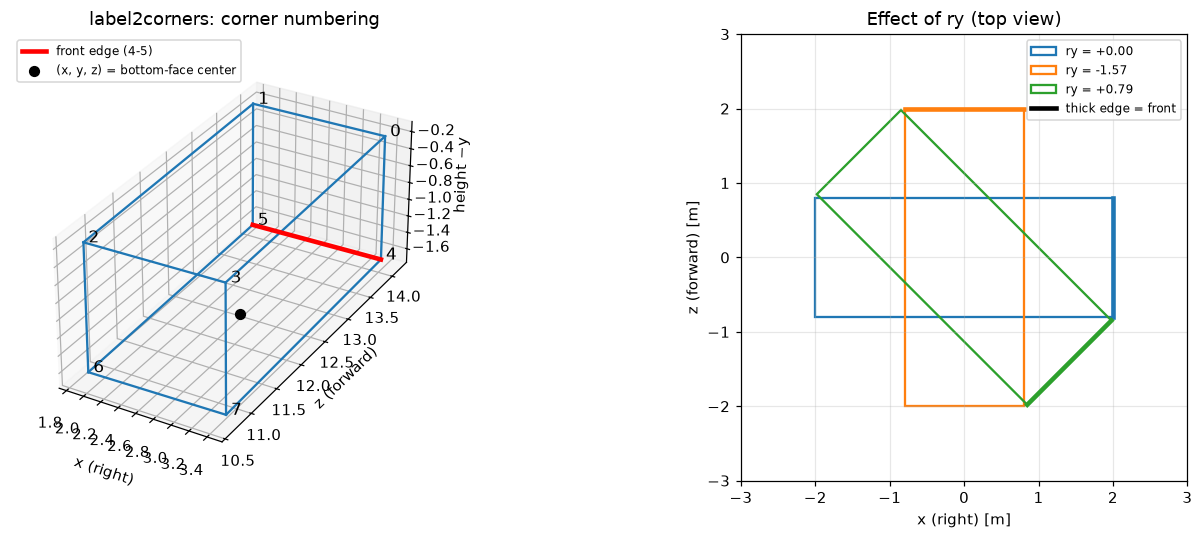

In [3]:
F = frame_data(ds.frames.index('002153'))
box = F['tgt'][2:3]
corners = label2corners(box)[0]
print('box (x, y, z, h, w, l, ry):', box[0])
display(pd.DataFrame(corners, columns=['x', 'y', 'z'], index=[f'corner {k}' for k in range(8)]).round(3))

fig = plt.figure(figsize=(14, 5))
ax = fig.add_subplot(1, 2, 1, projection='3d')
edges = [(0, 1), (0, 3), (0, 4), (2, 1), (2, 3), (2, 6), (5, 1), (5, 4), (5, 6), (7, 3), (7, 4), (7, 6)]
show = lambda p: (p[..., 0], p[..., 2], -p[..., 1])          # plot with "up" pointing up
for i, j in edges:
    ax.plot(*show(corners[[i, j]]), color='tab:blue')
ax.plot(*show(corners[[4, 5]]), color='red', lw=3, label='front edge (4-5)')
for k, c in enumerate(corners):
    ax.text(*show(c), f' {k}', fontsize=11)
ax.scatter(*show(box[:, :3]), color='k', s=40, label='(x, y, z) = bottom-face center')
ax.set_xlabel('x (right)'); ax.set_ylabel('z (forward)'); ax.set_zlabel('height −y')
ax.set_box_aspect(np.ptp(np.stack(show(corners), 1), 0)); ax.legend(loc='upper left', fontsize=8)
ax.set_title('label2corners: corner numbering')

ax = fig.add_subplot(1, 2, 2)
for ry, col in zip([0, -np.pi / 2, np.pi / 4], ['tab:blue', 'tab:orange', 'tab:green']):
    b = np.array([[0, 0, 0, 1.5, 1.6, 4.0, ry]])
    draw_bev(ax, b, col, label=f'ry = {ry:+.2f}')
ax.plot([], [], color='k', lw=3, label='thick edge = front')
ax.set_aspect('equal'); ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.grid(alpha=.3); ax.legend(fontsize=8)
ax.set_xlabel('x (right) [m]'); ax.set_ylabel('z (forward) [m]'); ax.set_title('Effect of ry (top view)')
plt.tight_layout(); plt.show()

## 2.1.2 3D IoU = top-view overlap × vertical overlap

Boxes only rotate around the vertical axis, so the overlap volume splits into two simple parts:
1. the **area** where the two rotated rectangles overlap in the top view (a convex polygon), and
2. the **height** where their vertical ranges `[y − h, y]` overlap.

Then `IoU = overlap volume / (volume A + volume B − overlap volume)`. Below: a proposal and its ground-truth car. The shaded polygon is drawn with shapely for illustration only; `get_iou` computes the area itself.

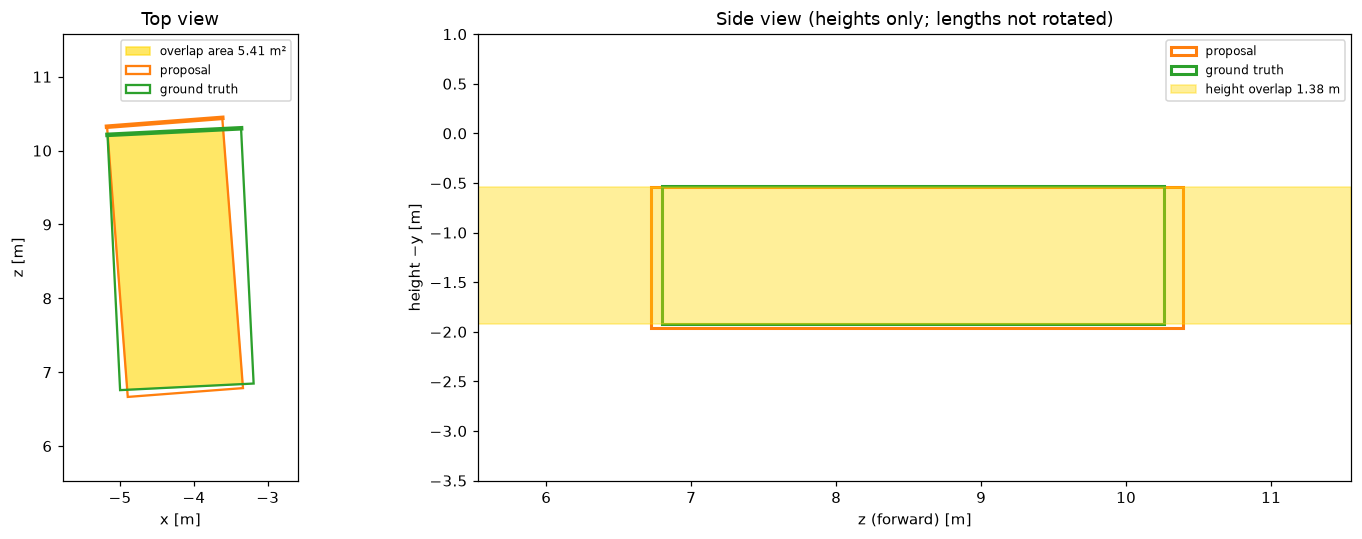

overlap volume = 5.415 m² × 1.384 m = 7.496 m³
IoU = 7.496 / (8.174 + 8.705 − 7.496) = 0.7989
get_iou gives                             0.7989


In [4]:
iou = get_iou(F['det'], F['tgt'])
p_idx, g_idx = np.unravel_index(np.argmax(np.where(iou < 0.8, iou, 0)), iou.shape)   # a good but imperfect match
P, G = F['det'][p_idx], F['tgt'][g_idx]
cP, cG = label2corners(P)[0], label2corners(G)[0]
polyP, polyG = shapely.Polygon(cP[4:8][:, [0, 2]]), shapely.Polygon(cG[4:8][:, [0, 2]])
inter_poly = polyP.intersection(polyG)
h_overlap = max(0, min(P[1], G[1]) - max(P[1] - P[3], G[1] - G[3]))
inter = inter_poly.area * h_overlap
volP, volG = np.prod(P[3:6]), np.prod(G[3:6])

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1, 1.3]})
ax = axes[0]
ax.add_patch(MplPolygon(np.array(inter_poly.exterior.coords), color='gold', alpha=.6, label=f'overlap area {inter_poly.area:.2f} m²'))
draw_bev(ax, P[None], 'tab:orange', label='proposal'); draw_bev(ax, G[None], 'tab:green', label='ground truth')
ax.set_aspect('equal'); ax.autoscale_view(); ax.margins(.3); ax.legend(fontsize=8)
ax.set_xlabel('x [m]'); ax.set_ylabel('z [m]'); ax.set_title('Top view')

ax = axes[1]
for b, col, name in [(P, 'tab:orange', 'proposal'), (G, 'tab:green', 'ground truth')]:
    ax.add_patch(plt.Rectangle((b[2] - b[5] / 2, -b[1]), b[5], b[3], fill=False, ec=col, lw=2, label=name))
ax.axhspan(-min(P[1], G[1]), -max(P[1] - P[3], G[1] - G[3]), color='gold', alpha=.4, label=f'height overlap {h_overlap:.2f} m')
ax.set_xlim(min(P[2], G[2]) - 3, max(P[2], G[2]) + 3); ax.set_ylim(-3.5, 1); ax.legend(fontsize=8)
ax.set_xlabel('z (forward) [m]'); ax.set_ylabel('height −y [m]'); ax.set_title('Side view (heights only; lengths not rotated)')
plt.tight_layout(); plt.show()

print(f'overlap volume = {inter_poly.area:.3f} m² × {h_overlap:.3f} m = {inter:.3f} m³')
print(f'IoU = {inter:.3f} / ({volP:.3f} + {volG:.3f} − {inter:.3f}) = {inter / (volP + volG - inter):.4f}')
print(f'get_iou gives                             {iou[p_idx, g_idx]:.4f}')

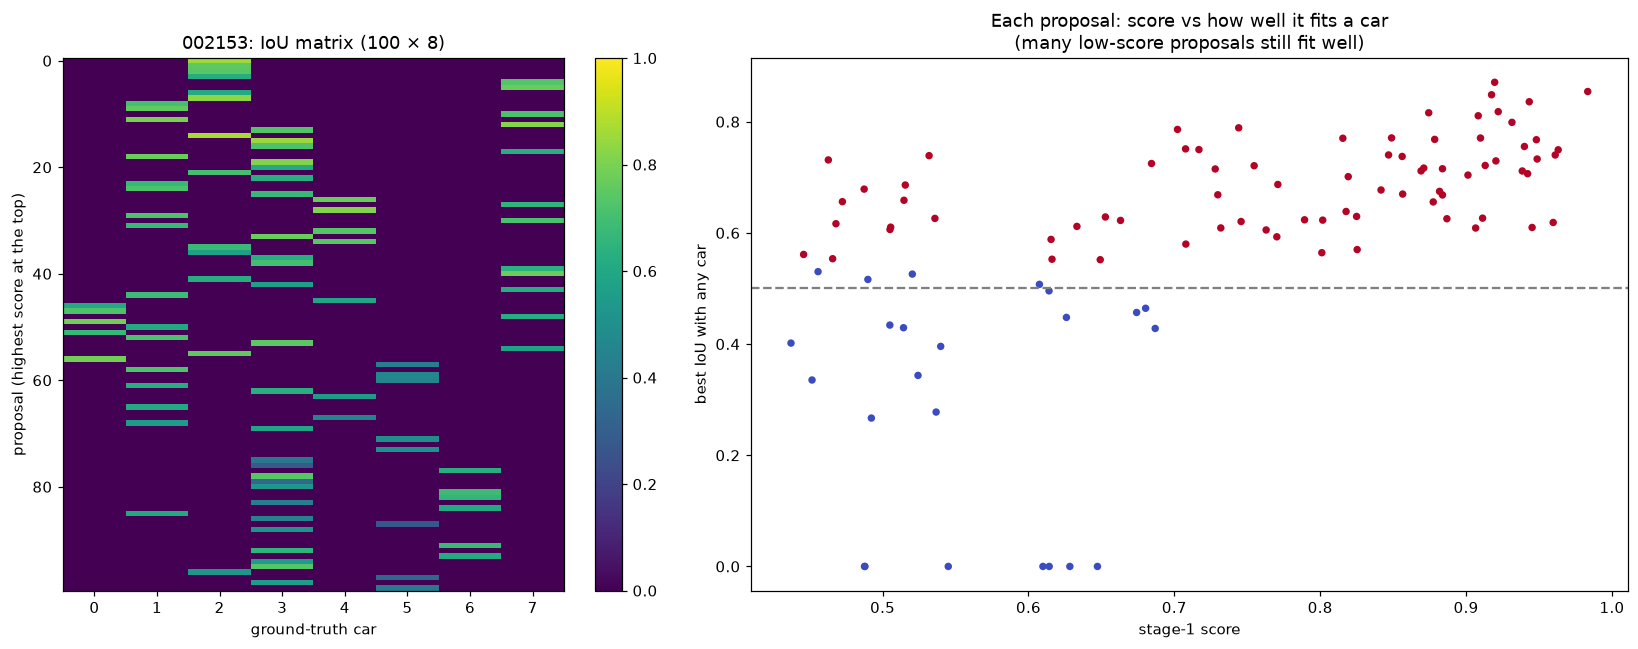

In [5]:
# The full IoU matrix of the frame: proposals (rows, sorted by stage-1 score) x ground-truth cars (columns)
order = np.argsort(-F['score'])
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1, 1.4]})
im = axes[0].imshow(iou[order], aspect='auto', cmap='viridis', vmin=0, vmax=1, interpolation='nearest')
axes[0].set_xlabel('ground-truth car'); axes[0].set_ylabel('proposal (highest score at the top)')
axes[0].set_title(f'{F["frame"]}: IoU matrix ({iou.shape[0]} × {iou.shape[1]})'); fig.colorbar(im, ax=axes[0])

ax = axes[1]
best = iou.max(1)
ax.scatter(F['score'], best, s=15, c=best >= 0.55, cmap='coolwarm')
ax.axhline(0.5, color='gray', ls='--'); ax.set_xlabel('stage-1 score'); ax.set_ylabel('best IoU with any car')
ax.set_title('Each proposal: score vs how well it fits a car\n(many low-score proposals still fit well)')
plt.tight_layout(); plt.show()

# Here in the left plot, there are shown the 100 proposals sorted by their stage-1 score (how likely they are to be a car).
# The colour indicates whether the proposal has a good match with any ground-truth car (according to the IoU). x-axis goes from 0 to 7 because there are 8 cars in that frame.

Each column (car) has several bright cells: several proposals cover the same car. Some columns may be completely dark, meaning a car with no good proposal. That's exactly what recall measures.

## 2.1.3 Recall

For one frame: `recall = TP / (TP + FN)`. A car is a true positive if its best proposal has IoU ≥ 0.5 (`config.yaml → eval.t_rpn_recall`), otherwise a false negative. The task asks for the **average over frames**. Frames without cars have no recall (`compute_recall` returns `nan`) and are skipped.

In [6]:
t_rpn = config['eval']['t_rpn_recall']
rows, cars = [], []
for i in range(len(ds)):
    d = frame_data(i)
    r = compute_recall(d['det'], d['tgt'], t_rpn)
    rows.append({'frame': d['frame'], 'cars': len(d['tgt']), 'recall': r})
    if len(d['tgt']):
        best = get_iou(d['det'], d['tgt']).max(0)
        lvl = difficulty(d['tgt_raw'])
        dist = np.hypot(d['tgt'][:, 0], d['tgt'][:, 2])
        cars += [{'frame': d['frame'], 'best IoU': b, 'difficulty': l, 'distance': s} for b, l, s in zip(best, lvl, dist)]
per_frame = pd.DataFrame(rows).set_index('frame')
cars = pd.DataFrame(cars)
print(f'Average recall@{t_rpn} over {per_frame.recall.notna().sum()} frames with cars: {per_frame.recall.mean():.4f}')
print(f'(car-level recall, all {len(cars)} cars pooled: {np.mean(cars["best IoU"] >= t_rpn):.4f})')
print(f'frames with perfect recall: {(per_frame.recall == 1).sum()}, frames without cars: {per_frame.recall.isna().sum()}')

Average recall@0.5 over 226 frames with cars: 0.9297
(car-level recall, all 936 cars pooled: 0.9220)
frames with perfect recall: 170, frames without cars: 24


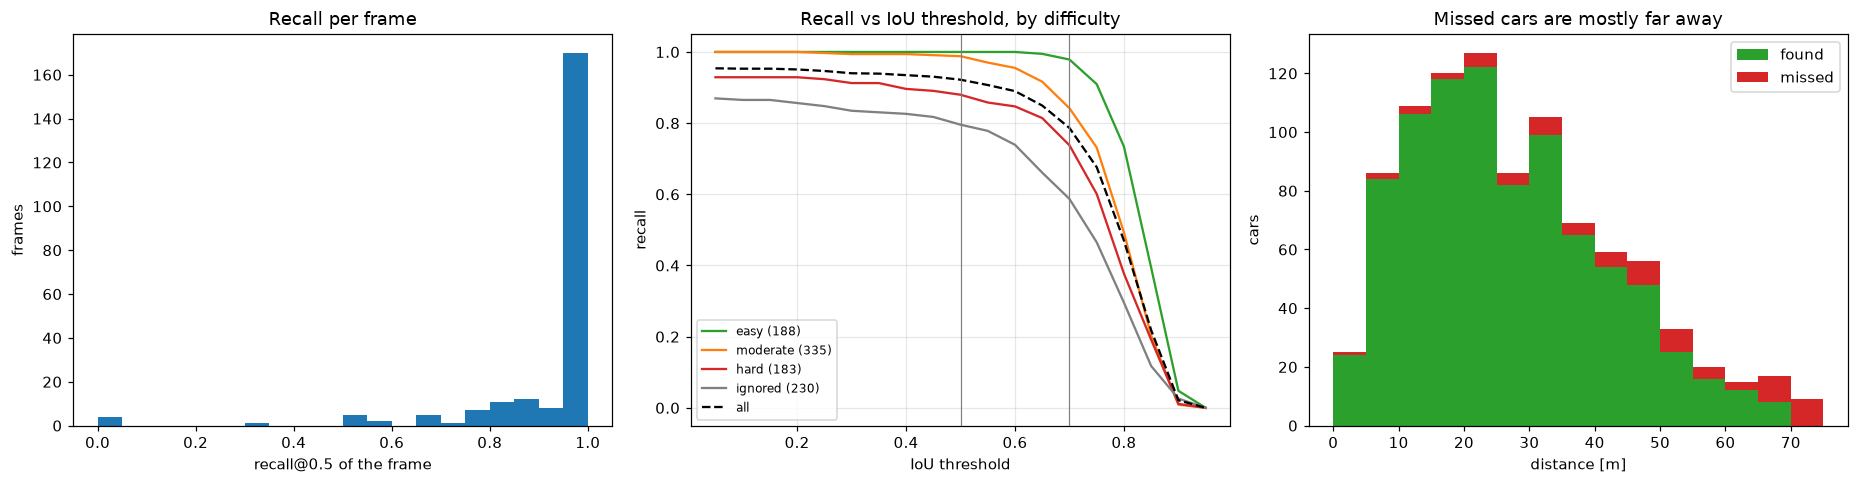

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].hist(per_frame.recall.dropna(), bins=20, range=(0, 1), color='tab:blue')
axes[0].set_xlabel(f'recall@{t_rpn} of the frame'); axes[0].set_ylabel('frames'); axes[0].set_title('Recall per frame')

thr = np.linspace(0.05, 0.95, 19)
names = {0: 'easy', 1: 'moderate', 2: 'hard', -1: 'ignored'}
for lvl, col in zip([0, 1, 2, -1], ['tab:green', 'tab:orange', 'tab:red', 'gray']):
    b = cars.loc[cars.difficulty == lvl, 'best IoU']
    axes[1].plot(thr, [np.mean(b >= t) for t in thr], color=col, label=f'{names[lvl]} ({len(b)})')
axes[1].plot(thr, [np.mean(cars['best IoU'] >= t) for t in thr], 'k--', label='all')
for t in [0.5, 0.7]:
    axes[1].axvline(t, color='gray', lw=.8)
axes[1].set_xlabel('IoU threshold'); axes[1].set_ylabel('recall'); axes[1].legend(fontsize=8); axes[1].grid(alpha=.3)
axes[1].set_title('Recall vs IoU threshold, by difficulty')

found = cars['best IoU'] >= t_rpn
axes[2].hist([cars.loc[found, 'distance'], cars.loc[~found, 'distance']], bins=15, range=(0, 75), stacked=True,
             color=['tab:green', 'tab:red'], label=['found', 'missed'])
axes[2].set_xlabel('distance [m]'); axes[2].set_ylabel('cars'); axes[2].legend(); axes[2].set_title('Missed cars are mostly far away')
plt.tight_layout(); plt.show()

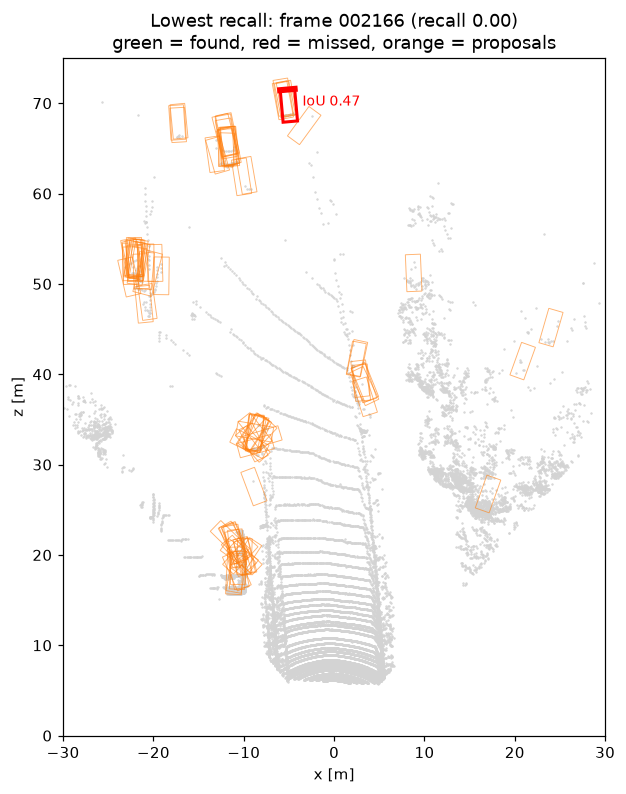

In [8]:
# The frame with the lowest recall, and why
worst = per_frame.recall.idxmin()
W = frame_data(ds.frames.index(worst))
best = get_iou(W['det'], W['tgt']).max(0)
fig, ax = plt.subplots(figsize=(9, 8))
ax.scatter(W['xyz'][:, 0], W['xyz'][:, 2], c='lightgray', s=0.3)
draw_bev(ax, W['det'], 'tab:orange', lw=.6, front=False, alpha=.6)
for b, v in zip(W['tgt'], best):
    draw_bev(ax, b[None], 'tab:green' if v >= t_rpn else 'red', lw=2)
    ax.text(b[0] + 1.5, b[2], f'IoU {v:.2f}', color='tab:green' if v >= t_rpn else 'red', fontsize=9)
ax.set_aspect('equal'); ax.set_xlim(-30, 30); ax.set_ylim(0, 75)
ax.set_xlabel('x [m]'); ax.set_ylabel('z [m]')
ax.set_title(f'Lowest recall: frame {worst} (recall {per_frame.recall[worst]:.2f})\ngreen = found, red = missed, orange = proposals')
plt.show()

In this frame the only labeled car is about 70 m away, and its best proposal reaches IoU 0.47, just under the threshold, so the frame's recall is 0. The many proposal clusters elsewhere probably sit on objects KITTI doesn't label as *Car* (vans, or regions marked "DontCare"). They show up as false positives at evaluation time even though stage 1 may be "right". Frames with very few cars make per-frame recall noisy, which is why the car-level recall is also printed above.

**Why recall is the right metric for the first stage** (report question): the second stage only refines the proposals it receives. A car without any proposal is lost for good, while an extra wrong proposal is cheap: stage 2 can lower its score and NMS removes duplicates. So stage 1 should above all *not miss cars* (recall). Average precision also rewards ranking and penalizes false positives, which are the second stage's job to fix. That's why stage 1 outputs 100–300 proposals per frame instead of a few confident ones.

---
# Task 2.2: RoI pooling

`roi_pool(pred, xyz, feat, config)` in `utils/task2.py` builds the second stage's input. For every proposal:
1. **Enlarge** the box by δ = 1 m on every side (`config.yaml → data.delta`), keeping its center fixed. The proposal is only roughly right, so the true car may stick out of it, and the surroundings (e.g. the ground under the car) help to refine it.
2. **Collect** the points (and their 128 features) inside the enlarged box.
3. **Resample** to exactly 512 points (`data.max_points`): random subset if there are more, all points plus random repeats if there are fewer. Boxes with no points are dropped.

Output: the kept boxes `(K', 7)`, points `(K', 512, 3)` and features `(K', 512, 128)`.

## 2.2.1 Enlarging a box

Because `(x, y, z)` is the bottom-face center and y points down, enlarging by δ means `h, w, l += 2δ` **and** `y += δ` (the bottom face moves down). Otherwise the box would grow only upwards.

original: [-4.255  1.96   8.554  1.424  1.564  3.669 -1.647]
enlarged: [-4.255  2.96   8.554  3.424  3.564  5.669 -1.647]
3D center before/after: [-4.255  1.248  8.554] [-4.255  1.248  8.554]


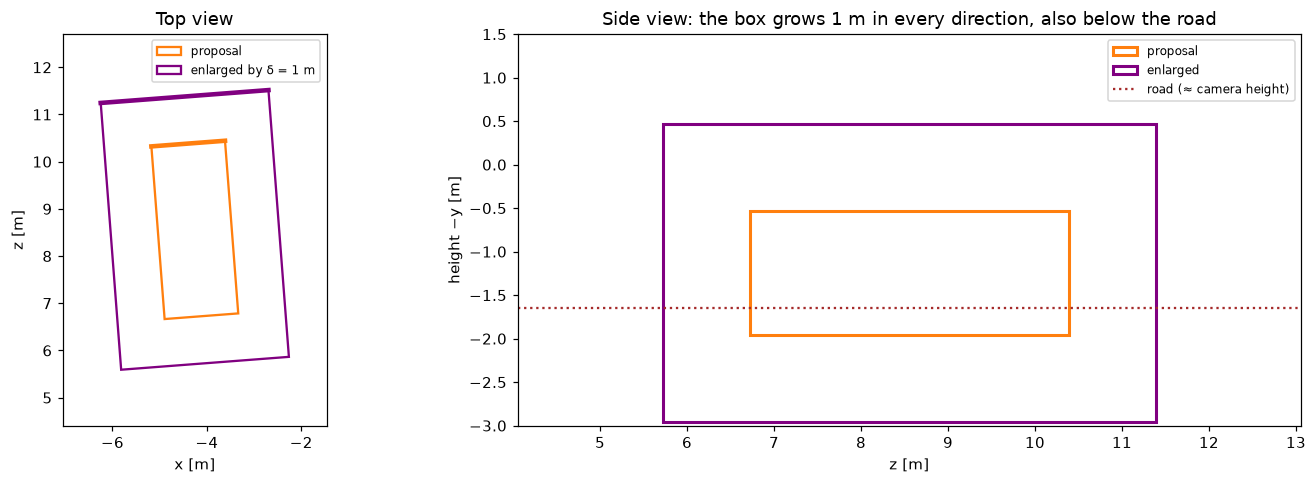

In [10]:
b = F['det'][p_idx:p_idx + 1]
e = enlarge_boxes(b, config['data']['delta'])
print('original:', b[0]); print('enlarged:', e[0])
print('3D center before/after:', label2corners(b)[0].mean(0), label2corners(e)[0].mean(0))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
draw_bev(axes[0], b, 'tab:orange', label='proposal'); draw_bev(axes[0], e, 'purple', label='enlarged by δ = 1 m')
axes[0].set_aspect('equal'); axes[0].autoscale_view(); axes[0].margins(.2); axes[0].legend(fontsize=8)
axes[0].set_xlabel('x [m]'); axes[0].set_ylabel('z [m]'); axes[0].set_title('Top view')
for bb, col, name in [(b[0], 'tab:orange', 'proposal'), (e[0], 'purple', 'enlarged')]:
    axes[1].add_patch(plt.Rectangle((bb[2] - bb[5] / 2, -bb[1]), bb[5], bb[3], fill=False, ec=col, lw=2, label=name))
axes[1].axhline(-1.65, color='brown', ls=':', label='road (≈ camera height)')
axes[1].set_xlim(b[0, 2] - 4.5, b[0, 2] + 4.5); axes[1].set_ylim(-3, 1.5); axes[1].set_aspect('equal'); axes[1].legend(fontsize=8)
axes[1].set_xlabel('z [m]'); axes[1].set_ylabel('height −y [m]'); axes[1].set_title('Side view: the box grows 1 m in every direction, also below the road')
plt.tight_layout(); plt.show()

## 2.2.2 How many points fall into each enlarged proposal?

25000 proposals: median 121 points per enlarged box
  discarded (0 points)       : 0
  repeated up to 512 (1-511) : 76.5%
  subsampled to 512 (> 512)    : 23.5%


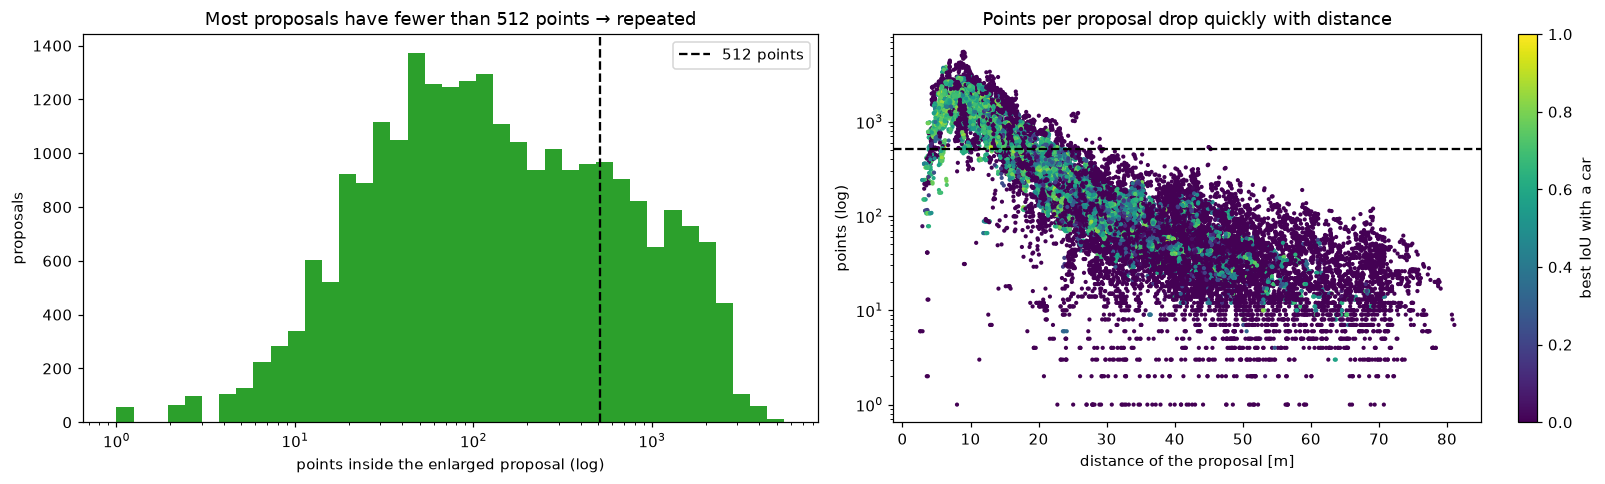

In [11]:
np.random.seed(0)
stats = []
for i in range(len(ds)):
    d = frame_data(i)
    n_in = points_in_boxes(d['xyz'], enlarge_boxes(d['det'], config['data']['delta'])).sum(1)
    best = get_iou(d['det'], d['tgt']).max(1) if len(d['tgt']) else np.zeros(len(d['det']))
    stats.append(pd.DataFrame({'frame': d['frame'], 'points': n_in, 'distance': np.hypot(d['det'][:, 0], d['det'][:, 2]),
                               'best IoU': best, 'score': d['score']}))
stats = pd.concat(stats, ignore_index=True)
M = config['data']['max_points']
print(f'{len(stats)} proposals: median {stats.points.median():.0f} points per enlarged box')
print(f'  discarded (0 points)       : {(stats.points == 0).sum()}')
print(f'  repeated up to {M} (1-{M - 1}) : {((stats.points > 0) & (stats.points < M)).mean() * 100:.1f}%')
print(f'  subsampled to {M} (> {M})    : {(stats.points > M).mean() * 100:.1f}%')

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].hist(stats.points, bins=np.logspace(0, np.log10(stats.points.max() + 1), 40), color='tab:green')
axes[0].axvline(M, color='k', ls='--', label=f'{M} points'); axes[0].set_xscale('log')
axes[0].set_xlabel('points inside the enlarged proposal (log)'); axes[0].set_ylabel('proposals'); axes[0].legend()
axes[0].set_title('Most proposals have fewer than 512 points → repeated')
sc = axes[1].scatter(stats.distance, stats.points, c=stats['best IoU'], s=3, cmap='viridis', vmin=0, vmax=1)
axes[1].axhline(M, color='k', ls='--'); axes[1].set_yscale('log')
axes[1].set_xlabel('distance of the proposal [m]'); axes[1].set_ylabel('points (log)')
axes[1].set_title('Points per proposal drop quickly with distance'); fig.colorbar(sc, ax=axes[1], label='best IoU with a car')
plt.tight_layout(); plt.show()

## 2.2.3 Three pooled RoIs from three scenes (report figure, cf. Fig. 5 left)

One near, one mid-range and one far proposal that match a car (IoU ≥ 0.55), each from a different frame. Points are colored by how often they appear among the 512: near cars are subsampled (every point once), far cars have few points that are repeated many times.

In [12]:
def pick(lo, hi, seed):
    c = stats[(stats['best IoU'] >= 0.55) & stats.distance.between(lo, hi)]
    return c.sample(1, random_state=seed).iloc[0]

choices = []
for lo, hi in [(5, 12), (20, 30), (40, 55)]:
    for seed in range(50):
        row = pick(lo, hi, seed)
        if row.frame not in [c[0] for c in choices]:
            break
    choices.append((row.frame, row.name))

examples, table = [], []
for fr, global_idx in choices:
    i = ds.frames.index(fr)
    d = frame_data(i)
    k = global_idx - stats.index[stats.frame == fr][0]          # proposal index inside the frame
    np.random.seed(0)
    vp, px, pf = roi_pool(d['det'][k:k + 1], d['xyz'], d['feat'], config['data'])
    examples.append((d, k, vp[0], px[0]))
    table.append({'frame': fr, **dict(zip(BOX_COLS, d['det'][k].round(3))), 'score': round(float(d['score'][k]), 3),
                  'points in box': int(stats.points[global_idx]), 'distinct among 512': len(np.unique(px[0], axis=0)),
                  'best IoU': round(float(stats['best IoU'][global_idx]), 3)})
pd.DataFrame(table).set_index('frame')

,x,y,z,h,w,l,ry,score,points in box,distinct among 512,best IoU
frame,,,,,,,,,,,
005156,-3.451,1.761,8.227000,1.620,1.629,3.835,1.552,0.940,2144,512,0.750
002248,-12.535,2.241,24.594999,1.480,1.651,4.124,1.600,0.832,248,248,0.597
007426,-2.770,0.863,45.117001,1.547,1.609,3.532,-1.803,0.439,43,43,0.669


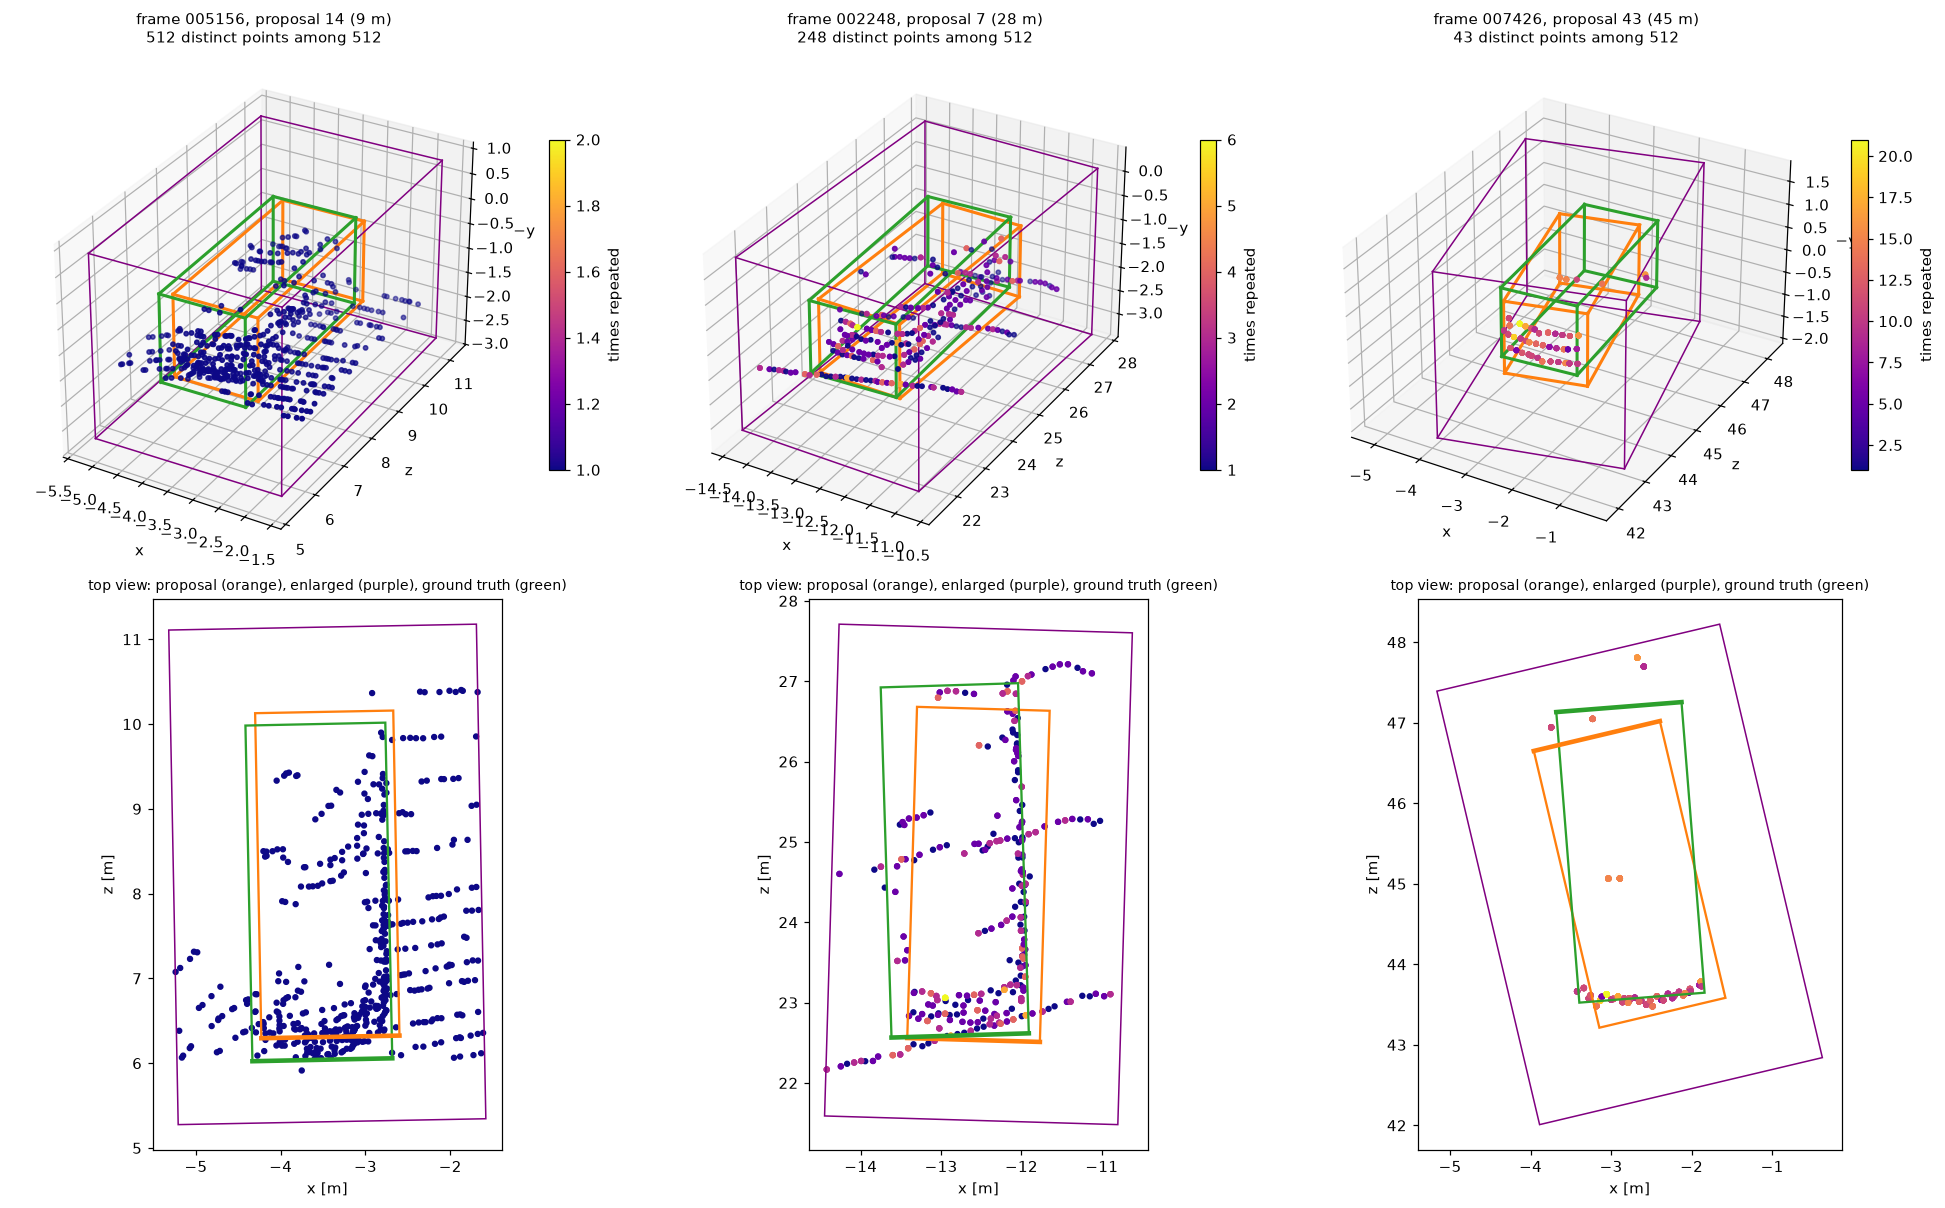

In [14]:
fig = plt.figure(figsize=(18, 11))
for col, (d, k, box, pts) in enumerate(examples):
    uniq, inv, cnt = np.unique(pts, axis=0, return_inverse=True, return_counts=True)
    times = cnt[inv.ravel()]
    tgt_idx = int(np.argmax(get_iou(box[None], d['tgt'])[0]))
    enl = enlarge_boxes(box[None], config['data']['delta'])

    ax = fig.add_subplot(2, 3, col + 1, projection='3d')
    vmax = max(2, times.max())
    sc = ax.scatter(pts[:, 0], pts[:, 2], -pts[:, 1], c=times, cmap='plasma', s=8, vmin=1, vmax=vmax)
    for bx, color, lw in [(box[None], 'tab:orange', 2), (enl, 'purple', 1), (d['tgt'][tgt_idx:tgt_idx + 1], 'tab:green', 2)]:
        c = label2corners(bx)[0]
        for i, j in edges:
            ax.plot(c[[i, j], 0], c[[i, j], 2], -c[[i, j], 1], color=color, lw=lw)
    cE = label2corners(enl)[0]
    ax.set_box_aspect(np.ptp(np.column_stack([cE[:, 0], cE[:, 2], -cE[:, 1]]), 0))
    ax.set_xlabel('x'); ax.set_ylabel('z'); ax.set_zlabel('−y')
    ax.set_title(f'frame {d["frame"]}, proposal {k} ({np.hypot(box[0], box[2]):.0f} m)\n'
                 f'{len(uniq)} distinct points among 512', fontsize=10)
    fig.colorbar(sc, ax=ax, shrink=.6, label='times repeated')

    ax = fig.add_subplot(2, 3, col + 4)
    ax.scatter(pts[:, 0], pts[:, 2], c=times, cmap='plasma', s=10, vmin=1, vmax=vmax)
    draw_bev(ax, enl, 'purple', lw=1, front=False); draw_bev(ax, box[None], 'tab:orange')
    draw_bev(ax, d['tgt'][tgt_idx:tgt_idx + 1], 'tab:green')
    ax.set_aspect('equal'); ax.set_xlabel('x [m]'); ax.set_ylabel('z [m]')
    ax.set_title('top view: proposal (orange), enlarged (purple), ground truth (green)', fontsize=9)
plt.tight_layout(); plt.show()

In the near example the car's outline is clear, with ground points around it from the enlargement. In the far one only a handful of points hit the car, and the network sees mostly copies of them. This is the hardest case for the refinement.

## 2.2.4 What the pooled features tell the second stage

The second stage gets 512 points × 128 features per proposal. As a quick check of how informative they are: average the features of each RoI and project all RoIs of the split onto 2 PCA directions, colored by how well the proposal fits a car.

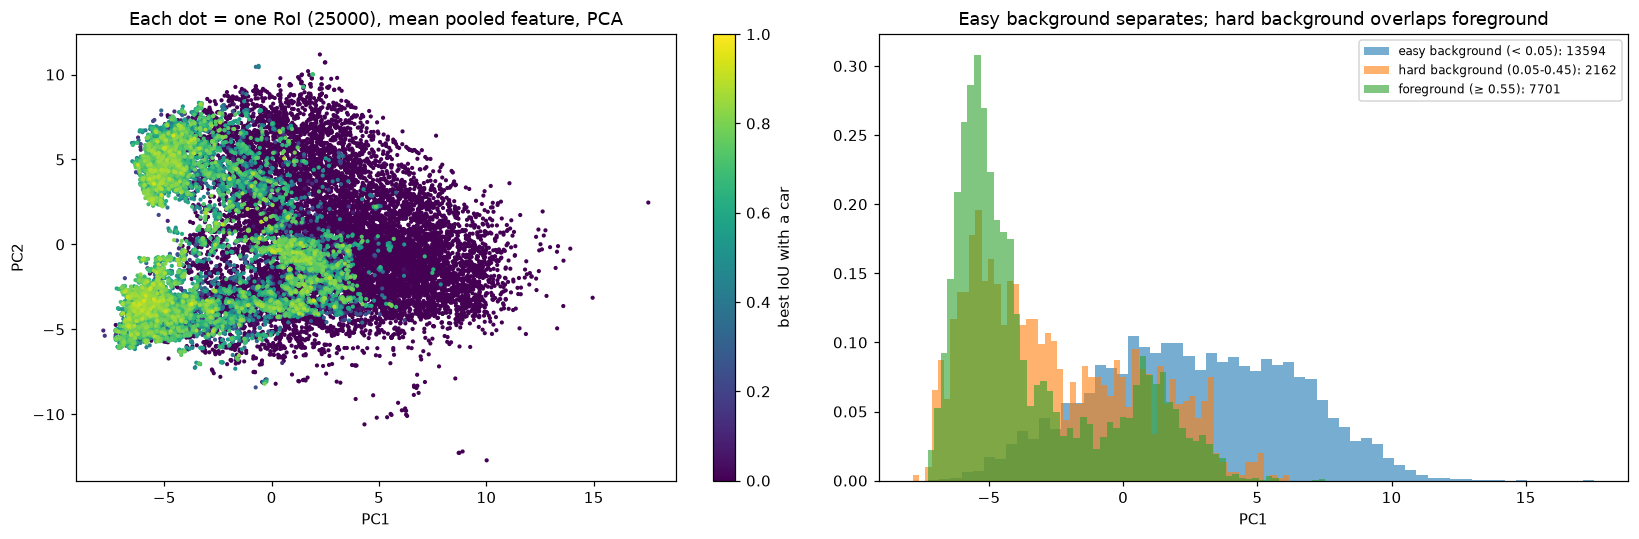

In [12]:
np.random.seed(0)
roi_mean, roi_iou = [], []
for i in range(len(ds)):
    d = frame_data(i)
    vp, px, pf = roi_pool(d['det'], d['xyz'], d['feat'], config['data'])
    roi_mean.append(np.log1p(pf.astype(np.float32)).mean(1))
    roi_iou.append(get_iou(vp, d['tgt']).max(1) if len(d['tgt']) else np.zeros(len(vp)))
roi_mean, roi_iou = np.concatenate(roi_mean), np.concatenate(roi_iou)
X = (roi_mean - roi_mean.mean(0)) / (roi_mean.std(0) + 1e-6)
_, S, Vt = np.linalg.svd(X, full_matrices=False)
pc = X @ Vt[:2].T

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
order = np.argsort(roi_iou)
sc = axes[0].scatter(pc[order, 0], pc[order, 1], c=roi_iou[order], s=3, cmap='viridis', vmin=0, vmax=1)
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2'); fig.colorbar(sc, ax=axes[0], label='best IoU with a car')
axes[0].set_title(f'Each dot = one RoI ({len(pc)}), mean pooled feature, PCA')
for lo, hi, col, name in [(0, 0.05, 'tab:blue', 'easy background (< 0.05)'), (0.05, 0.45, 'tab:orange', 'hard background (0.05-0.45)'),
                          (0.55, 1.01, 'tab:green', 'foreground (≥ 0.55)')]:
    sel = (roi_iou >= lo) & (roi_iou < hi)
    axes[1].hist(pc[sel, 0], bins=60, alpha=.6, density=True, color=col, label=f'{name}: {sel.sum()}')
axes[1].set_xlabel('PC1'); axes[1].legend(fontsize=8); axes[1].set_title('Easy background separates; hard background overlaps foreground')
plt.tight_layout(); plt.show()

Even this crude summary (one average per RoI) separates **easy background** (RoIs far from any car) from foreground. **Hard background** RoIs, which partly overlap a car, mostly look like foreground: their points *are* car points, just not well framed by the box. Telling them apart needs the full point layout inside the RoI, which is what the second-stage network learns. It's also why Task 2.3 deliberately feeds the network hard background samples: with easy ones only, it would never learn this distinction.

---
# Task 2.3: matching proposals to targets and sampling 64 per scene

`sample_proposals(pred, target, xyz, feat, config, train)` in `utils/task3.py`:
1. **Match** each proposal with the ground-truth car it overlaps most, and keep that IoU.
2. **Label** it by that IoU (thresholds from `config.yaml → data`):

| Label | IoU | What the box contains | Why |
|---|---|---|---|
| foreground | ≥ 0.55 | a car, reasonably framed | positives to learn from |
| *ignored* | 0.45–0.55 | half right, half wrong | too ambiguous to label either way |
| hard background | 0.05–0.45 | part of a car, badly framed | looks like a car → *hard to reject* |
| easy background | < 0.05 | no car (road, wall, tree…) | obviously not a car → *easy to reject* |

"Easy/hard" is about how hard the sample is to **classify** for the second stage, not how hard the car is to detect.

3. **Training only, sample 64 per scene**: at most 32 foreground; the background half easy, half hard (odd extra from easy); repeat if a pool is too small, sample randomly if it's too big. Each car's best proposal is an **extra foreground sample** even below 0.55, so every car contributes a positive.
4. **Validation**: all proposals, no sampling.

frame 002153: 8 cars, 100 proposals; foreground pool = 76 + 8 extra = 84 -> 32 sampled


,proposals in the frame,sampled (of 64)
easy background,7,16
foreground,76,32
hard background,10,16
ignored,7,0


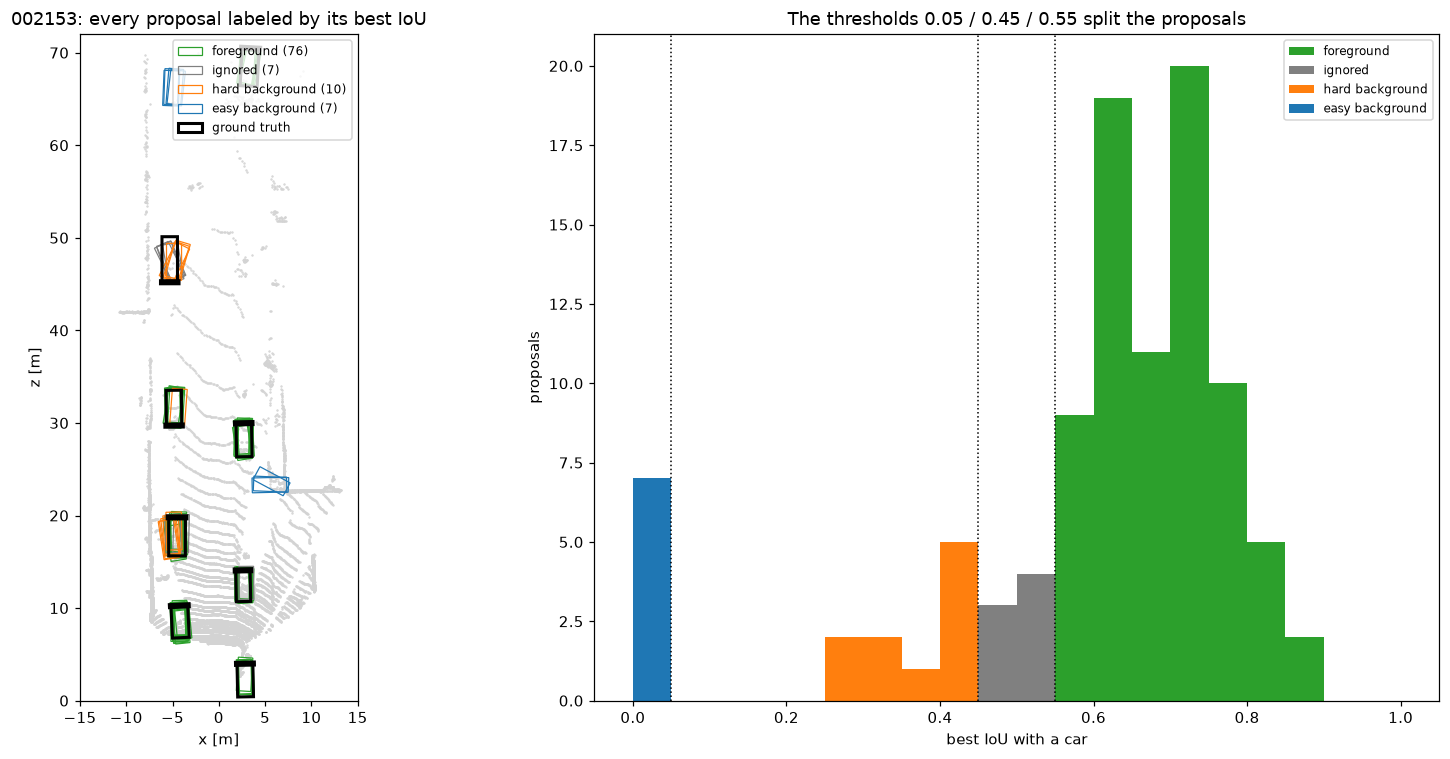

In [13]:
from utils.task3 import sample_proposals, assign_targets, split_proposals

dcfg = config['data']
assigned, best_iou, iou_mat = assign_targets(F['det'], F['tgt'])
fg, easy_bg, hard_bg = split_proposals(best_iou, iou_mat, dcfg)
extra = iou_mat.argmax(0)                               # best proposal of each car
label = np.full(len(best_iou), 'ignored', dtype=object)
label[best_iou >= dcfg['t_fg_lb']] = 'foreground'
label[(best_iou >= dcfg['t_bg_hard_lb']) & (best_iou < dcfg['t_bg_up'])] = 'hard background'
label[best_iou < dcfg['t_bg_hard_lb']] = 'easy background'
COLORS = {'foreground': 'tab:green', 'ignored': 'gray', 'hard background': 'tab:orange', 'easy background': 'tab:blue'}

# Sample once; passing proposal ids as "xyz" tells us which proposals were picked
np.random.seed(0)
_, ids, _, s_iou = sample_proposals(F['det'], F['tgt'], np.arange(len(F['det'])), np.arange(len(F['det'])), dcfg, train=True)
picked = pd.Series(label[ids]).value_counts()
summary = pd.DataFrame({'proposals in the frame': pd.Series(label).value_counts(), 'sampled (of 64)': picked}).fillna(0).astype(int)
print(f'frame {F["frame"]}: {len(F["tgt"])} cars, {len(F["det"])} proposals; '
      f'foreground pool = {np.sum(best_iou >= dcfg["t_fg_lb"])} + {len(extra)} extra = {len(fg)} -> {min(len(fg), 32)} sampled')
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [1.2, 1]})
ax = axes[0]
ax.scatter(F['xyz'][:, 0], F['xyz'][:, 2], c='lightgray', s=0.3)
for name, col in COLORS.items():
    sel = label == name
    if sel.any():
        draw_bev(ax, F['det'][sel], col, lw=.8, front=False, label=f'{name} ({sel.sum()})')
draw_bev(ax, F['tgt'], 'k', lw=2, label='ground truth')
ax.set_aspect('equal'); ax.set_xlim(-15, 15); ax.set_ylim(0, 72); ax.legend(fontsize=8, loc='upper right')
ax.set_xlabel('x [m]'); ax.set_ylabel('z [m]'); ax.set_title(f'{F["frame"]}: every proposal labeled by its best IoU')

ax = axes[1]
ax.hist([best_iou[label == n] for n in COLORS], bins=20, range=(0, 1), stacked=True, color=list(COLORS.values()), label=list(COLORS))
for t in [dcfg['t_bg_hard_lb'], dcfg['t_bg_up'], dcfg['t_fg_lb']]:
    ax.axvline(t, color='k', ls=':', lw=1)
ax.set_xlabel('best IoU with a car'); ax.set_ylabel('proposals'); ax.legend(fontsize=8)
ax.set_title('The thresholds 0.05 / 0.45 / 0.55 split the proposals')
plt.tight_layout(); plt.show()

## 2.3.1 What sampling changes, over the whole split

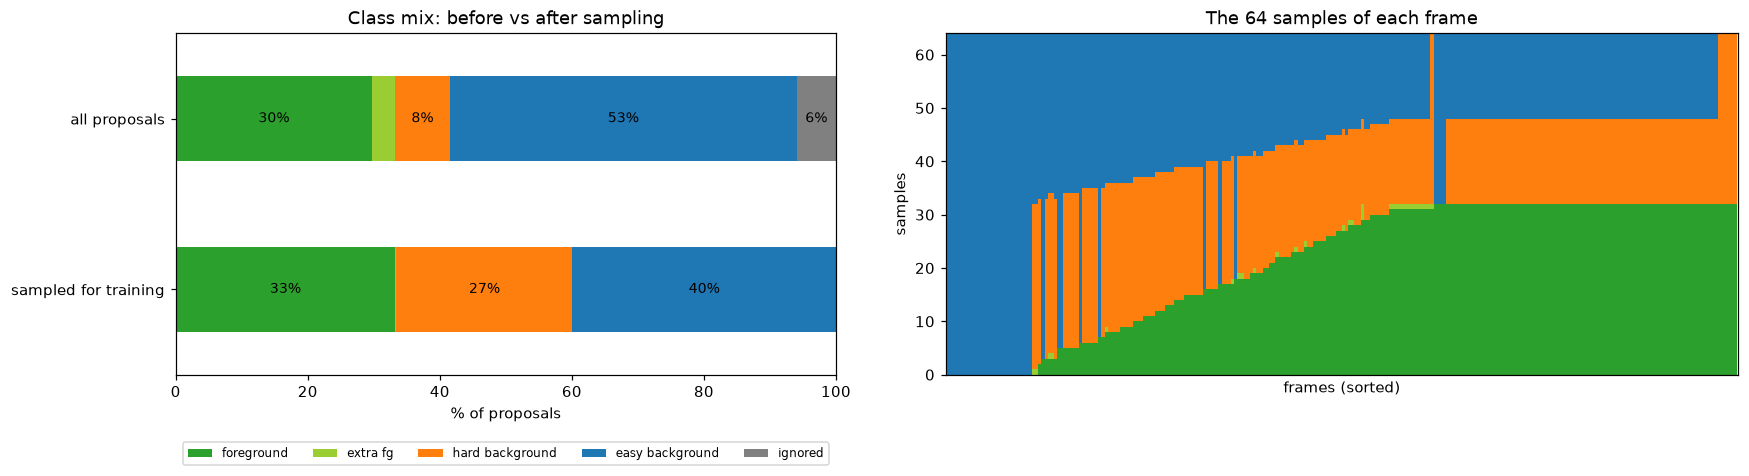

cars whose best proposal is below 0.55 and get a positive only thanks to the extra-foreground rule: 44 (best IoU between 0.08 and 0.55)


In [14]:
np.random.seed(0)
avail, sampled, rescued = [], [], []
for i in range(len(ds)):
    d = frame_data(i)
    tgt = ds.get_data(i, 'target')                   # with the dummy box for frames without cars, as in training
    a, b_iou, m = assign_targets(d['det'], tgt)
    f_, e_, h_ = split_proposals(b_iou, m, dcfg)
    avail.append({'foreground': np.sum(b_iou >= dcfg['t_fg_lb']), 'extra fg': len(f_) - np.sum(b_iou >= dcfg['t_fg_lb']),
                  'hard background': len(h_), 'easy background': len(e_),
                  'ignored': np.sum((b_iou >= dcfg['t_bg_up']) & (b_iou < dcfg['t_fg_lb']))})
    _, ids, _, s_iou = sample_proposals(d['det'], tgt, np.arange(len(d['det'])), np.arange(len(d['det'])), dcfg, train=True)
    # number of foreground samples, same rule as sample_proposals (they come first in the output)
    n_fg = min(len(f_), dcfg['num_fg_sample']) if len(f_) and len(e_) + len(h_) else (64 if len(f_) else 0)
    sampled.append({'foreground': np.sum(s_iou[:n_fg] >= dcfg['t_fg_lb']),
                    'extra fg': np.sum(s_iou[:n_fg] < dcfg['t_fg_lb']),
                    'hard background': np.sum((s_iou[n_fg:] >= dcfg['t_bg_hard_lb'])),
                    'easy background': np.sum(s_iou[n_fg:] < dcfg['t_bg_hard_lb'])})
    if len(d['tgt']):
        rescued.extend(m.max(0)[(m.max(0) > 0) & (m.max(0) < dcfg['t_fg_lb'])])
avail, sampled = pd.DataFrame(avail), pd.DataFrame(sampled)

cols = ['foreground', 'extra fg', 'hard background', 'easy background', 'ignored']
colors = ['tab:green', 'yellowgreen', 'tab:orange', 'tab:blue', 'gray']
share = pd.DataFrame({'all proposals': avail[cols].sum() / avail[cols].sum().sum(),
                      'sampled for training': sampled.reindex(columns=cols, fill_value=0).sum() / (64 * len(ds))}).T * 100
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={'width_ratios': [1, 1.2]})
share.plot.barh(stacked=True, color=colors, ax=axes[0], legend=False)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt=lambda v: f'{v:.0f}%' if v >= 4 else '', label_type='center', fontsize=9)
axes[0].set_xlabel('% of proposals'); axes[0].set_title('Class mix: before vs after sampling'); axes[0].invert_yaxis()
axes[0].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=5)

sampled.reindex(columns=cols[:4]).sort_values(['foreground', 'hard background']).reset_index(drop=True).plot.bar(
    stacked=True, width=1.0, color=colors[:4], ax=axes[1], legend=False)
axes[1].set_xticks([]); axes[1].set_xlabel('frames (sorted)'); axes[1].set_ylabel('samples')
axes[1].set_title('The 64 samples of each frame')
plt.tight_layout(); plt.show()
print(f'cars whose best proposal is below 0.55 and get a positive only thanks to the extra-foreground rule: {len(rescued)} '
      f'(best IoU between {min(rescued):.2f} and {max(rescued):.2f})')

Sampling roughly flips the mix: hard background goes from under a tenth of the proposals to about a quarter of the training samples, and easy background is no longer the majority. The per-frame bars show the special cases: frames without cars are all easy background, and frames with only a few proposals near cars contain repeats.

## 2.3.2 Report figure: a scene with all proposals and only the pooled points

The report asks for a training-set frame; here a minival frame is used since that's what's available locally. Only the points that fall into at least one enlarged proposal are shown, which is all the second stage ever sees of the scene.

frame 002153: 100 proposals, 5207 distinct pooled points out of 16384 (32% of the cloud)


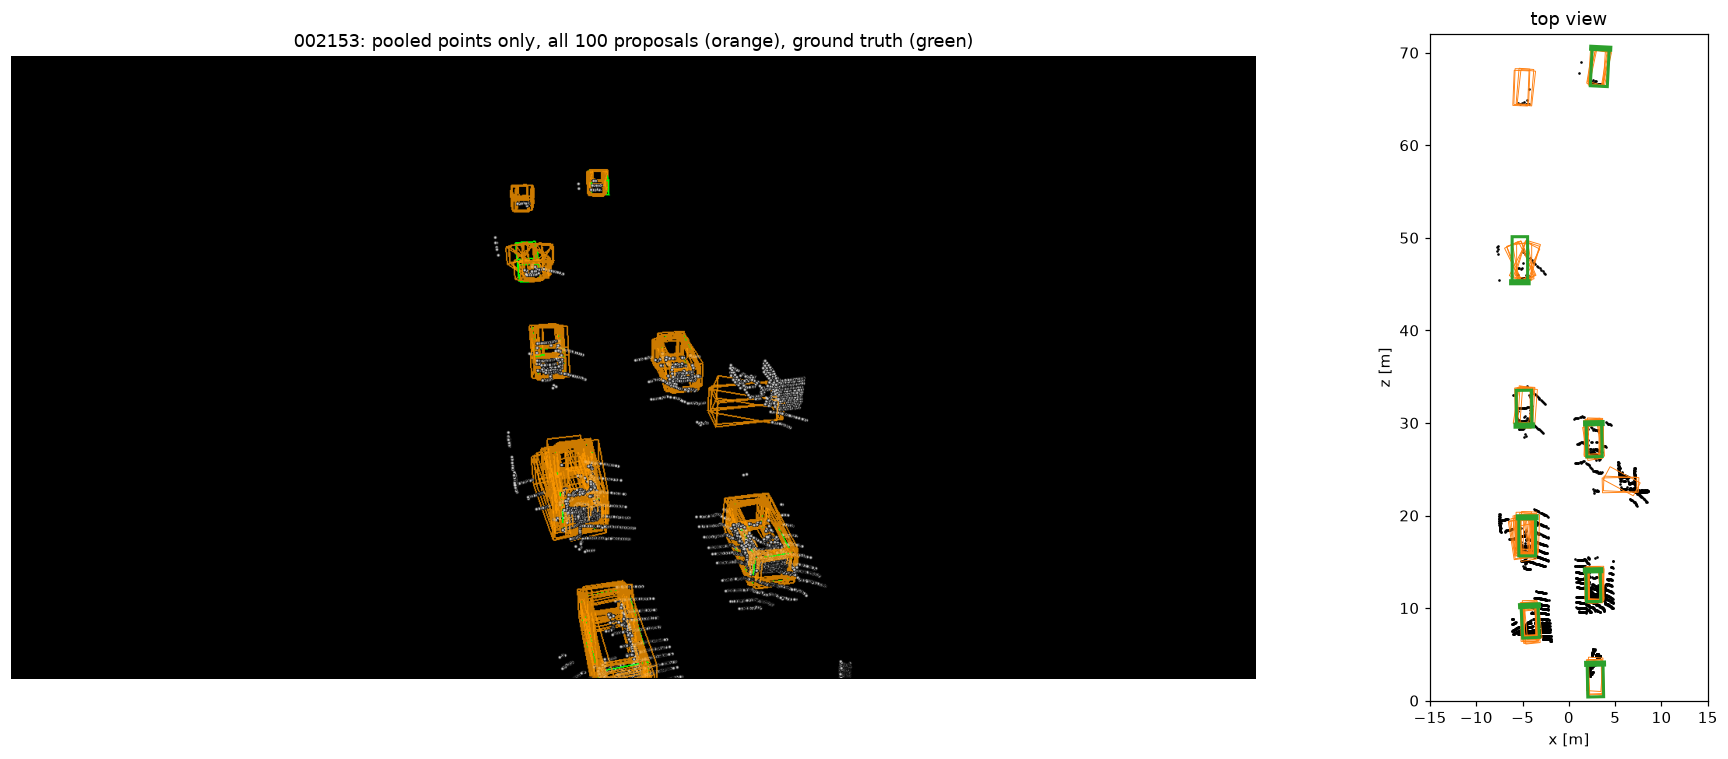

In [15]:
import vispy
vispy.use('pyqt6')
from vispy.scene import SceneCanvas, visuals, cameras

np.random.seed(0)
vp, px, pf = roi_pool(F['det'], F['xyz'], F['feat'], dcfg)
pooled = np.unique(px.reshape(-1, 3), axis=0)
print(f'frame {F["frame"]}: {len(vp)} proposals, {len(pooled)} distinct pooled points out of {len(F["xyz"])} '
      f'({100 * len(pooled) / len(F["xyz"]):.0f}% of the cloud)')

EDGES = np.array(edges)
to_display = lambda p: np.stack([p[..., 2], -p[..., 0], -p[..., 1]], -1)       # (forward, left, up) for vispy
canvas = SceneCanvas(size=(1600, 800), show=False, bgcolor='black')
view = canvas.central_widget.add_view()
view.camera = cameras.TurntableCamera(up='z', azimuth=-100, elevation=30, distance=45, center=(28, 0, -1))
mk = visuals.Markers(); mk.set_data(to_display(pooled), face_color=(0.85, 0.85, 0.85, 1), edge_width=0, size=3); view.add(mk)
for boxes, color in [(vp, (1, .6, 0, .8)), (F['tgt'], (0, 1, 0, 1))]:
    c = to_display(label2corners(boxes))
    line = visuals.Line(); line.set_data(c.reshape(-1, 3), connect=np.concatenate([EDGES + 8 * k for k in range(len(c))]), color=color, width=2)
    view.add(line)
img = canvas.render()

fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={'width_ratios': [1.6, 1]})
axes[0].imshow(img); axes[0].axis('off')
axes[0].set_title(f'{F["frame"]}: pooled points only, all {len(vp)} proposals (orange), ground truth (green)')
axes[1].scatter(pooled[:, 0], pooled[:, 2], c='k', s=0.5)
draw_bev(axes[1], vp, 'tab:orange', lw=.6, front=False); draw_bev(axes[1], F['tgt'], 'tab:green', lw=2)
axes[1].set_aspect('equal'); axes[1].set_xlim(-15, 15); axes[1].set_ylim(0, 72)
axes[1].set_xlabel('x [m]'); axes[1].set_ylabel('z [m]'); axes[1].set_title('top view')
plt.tight_layout(); plt.show()

## 2.3.3 The report questions

**1. Why is such a sampling scheme required?** Proposals are very unbalanced: most are easy background, few are hard background, and the number of positives varies a lot from scene to scene. The scheme gives every scene the same number of samples, a controlled balance of positives and negatives, and enough hard negatives, so the network learns the distinctions that matter instead of whatever is most common.

**2. What if we sampled randomly from all proposals?** The samples would follow the raw mix: mostly easy background, few hard cases, and a number of positives that depends on the scene (sometimes none). The classifier would learn the trivial "no car points → background" rule and score badly framed boxes on cars too high. The regression head would also get few, irregular positive examples.

**3. What if we never sampled easy background?** The network would only see negatives that sit on cars. It would never learn that a wall, a hedge or a pole is not a car, so at test time, where most proposals are such easy cases, it would give some of them high scores: more false positives, lower precision.

**4. What if foreground were IoU > 0.5 and background everything else?** Proposals just above and just below 0.5 look nearly identical but would get opposite labels. That's noisy, contradictory supervision right at the decision boundary, and the classifier becomes less reliable. The 0.45–0.55 gap keeps those ambiguous cases out of training (and the stricter 0.6 / 0.45 thresholds of the classification loss in Task 2.4 go further in the same direction).

**5. Why match each proposal with its highest-IoU ground truth?** The regression head must learn which box to move the proposal *to*. The best-overlapping car is the one the proposal is most likely trying to cover; matching it with a different car would ask the network to jump to a far-away box it has little evidence for. That IoU is also what decides foreground or background, so the label and the regression target always refer to the same car.

---
# Task 2.4: the two losses

The second-stage network has two heads per proposal: a **box** (7 numbers) and a **confidence** (one sigmoid output in [0, 1]). `utils/task4.py` defines a loss for each. The key point is that each loss only uses the samples it can learn something from:

| Loss | Used samples | Formula |
|---|---|---|
| `RegressionLoss` | positives only: IoU ≥ 0.55 (`loss.positive_reg_lb`) | `SmoothL1(x,y,z) + 3 · SmoothL1(h,w,l) + SmoothL1(ry)` |
| `ClassificationLoss` | positives IoU ≥ 0.6 → label 1, negatives IoU ≤ 0.45 → label 0 | binary cross-entropy |

* **Why regress only positives?** A background proposal often has no car inside; asking the network to move it onto its "assigned" car (which may be meters away or not visible in the RoI at all) would be noise.
* **Why ×3 on the size?** Box size errors hurt IoU (and so AP) a lot, while their values are small and similar for all cars; the weight makes the network take them seriously.
* **Why the stricter 0.6 / 0.45 for classification?** Proposals in between are ambiguous; leaving them out avoids contradictory labels (same idea as the 0.45–0.55 gap in Task 2.3).

The course test `python tests/test.py --task 4` passes (it needs a config whose `root_dir` contains a `project2_val` split).

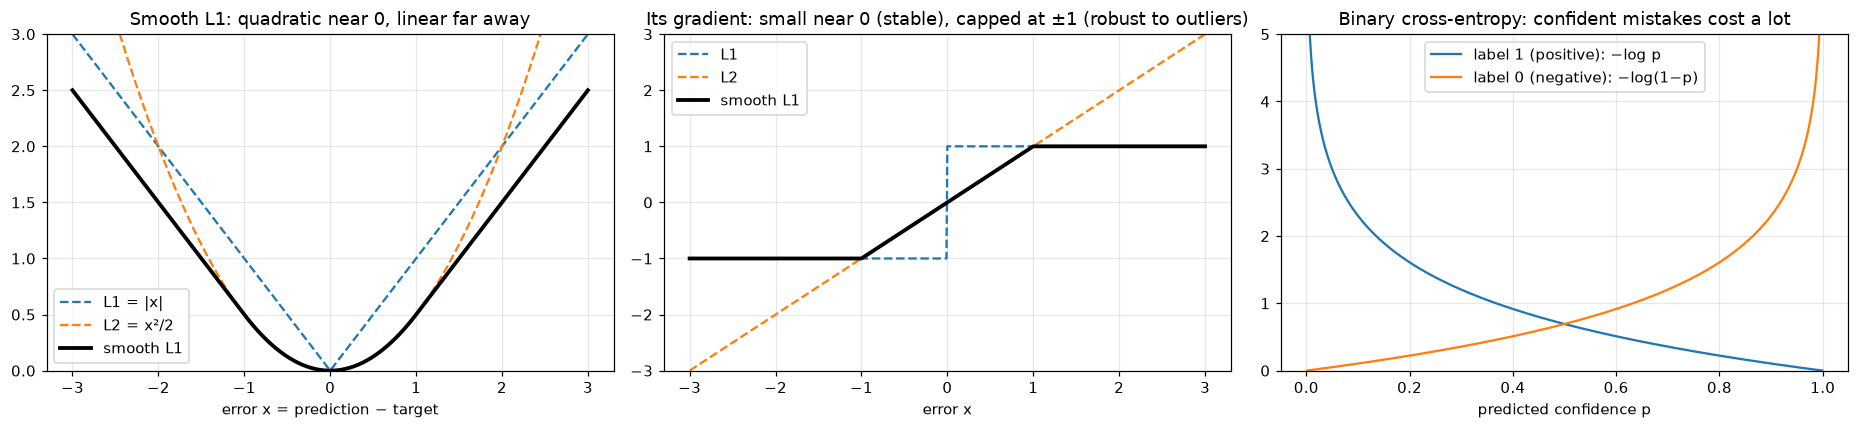

In [16]:
import torch
from utils.task4 import RegressionLoss, ClassificationLoss

x = torch.linspace(-3, 3, 601)
sl1 = torch.nn.SmoothL1Loss(reduction='none')(x, torch.zeros_like(x))
p = torch.linspace(0.001, 0.999, 500)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].plot(x, x.abs(), '--', label='L1 = |x|'); axes[0].plot(x, 0.5 * x ** 2, '--', label='L2 = x²/2')
axes[0].plot(x, sl1, 'k', lw=2.5, label='smooth L1'); axes[0].set_ylim(0, 3); axes[0].legend(); axes[0].grid(alpha=.3)
axes[0].set_xlabel('error x = prediction − target'); axes[0].set_title('Smooth L1: quadratic near 0, linear far away')
axes[1].plot(x, torch.sign(x), '--', label='L1'); axes[1].plot(x, x, '--', label='L2')
axes[1].plot(x, torch.clamp(x, -1, 1), 'k', lw=2.5, label='smooth L1'); axes[1].set_ylim(-3, 3); axes[1].legend(); axes[1].grid(alpha=.3)
axes[1].set_xlabel('error x'); axes[1].set_title('Its gradient: small near 0 (stable), capped at ±1 (robust to outliers)')
axes[2].plot(p, -torch.log(p), label='label 1 (positive): −log p'); axes[2].plot(p, -torch.log(1 - p), label='label 0 (negative): −log(1−p)')
axes[2].set_ylim(0, 5); axes[2].legend(); axes[2].grid(alpha=.3)
axes[2].set_xlabel('predicted confidence p'); axes[2].set_title('Binary cross-entropy: confident mistakes cost a lot')
plt.tight_layout(); plt.show()

## 2.4.1 Which training samples each loss sees

Using the 64 sampled proposals per scene from Task 2.3 over all of minival:

16000 training samples (250 scenes × 64)
  regression loss uses     :  33.2%  (IoU ≥ 0.55)
  classification positives :  28.4%  (IoU ≥ 0.6)
  classification negatives :  66.7%  (IoU ≤ 0.45)
  ignored by classification:   5.0%


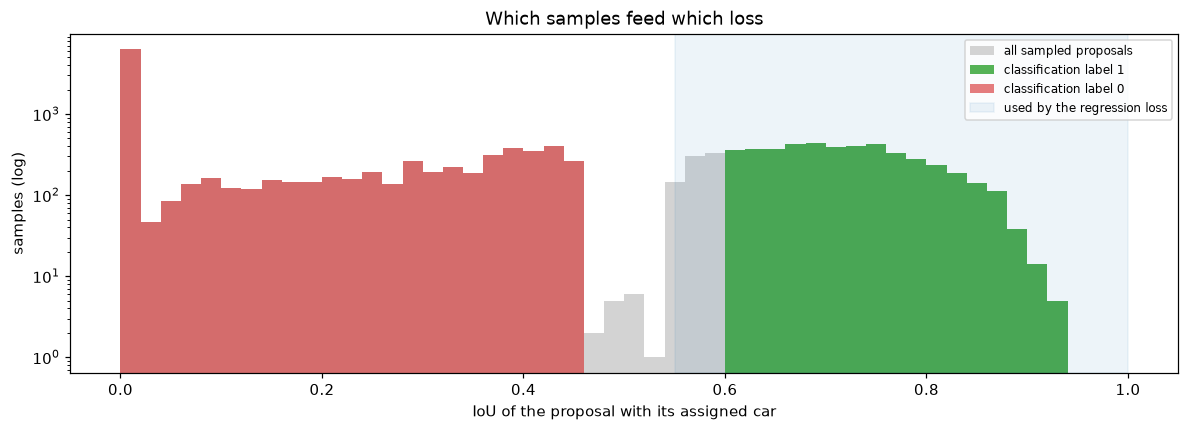

In [17]:
lcfg = config['loss']
np.random.seed(0)
S_iou, S_prop, S_tgt, S_score = [], [], [], []
for i in range(len(ds)):
    d = frame_data(i)
    tgt = ds.get_data(i, 'target')
    a, ids, _, s_iou = sample_proposals(d['det'], tgt, np.arange(len(d['det'])), np.arange(len(d['det'])), dcfg, train=True)
    S_iou.append(s_iou); S_prop.append(d['det'][ids]); S_tgt.append(a); S_score.append(d['score'][ids])
S_iou, S_prop, S_tgt, S_score = map(np.concatenate, (S_iou, S_prop, S_tgt, S_score))

reg_used = S_iou >= lcfg['positive_reg_lb']
cls_pos, cls_neg = S_iou >= lcfg['positive_cls_lb'], S_iou <= lcfg['negative_cls_ub']
print(f'{len(S_iou)} training samples ({len(ds)} scenes × 64)')
print(f'  regression loss uses     : {reg_used.mean() * 100:5.1f}%  (IoU ≥ {lcfg["positive_reg_lb"]})')
print(f'  classification positives : {cls_pos.mean() * 100:5.1f}%  (IoU ≥ {lcfg["positive_cls_lb"]})')
print(f'  classification negatives : {cls_neg.mean() * 100:5.1f}%  (IoU ≤ {lcfg["negative_cls_ub"]})')
print(f'  ignored by classification: {(~cls_pos & ~cls_neg).mean() * 100:5.1f}%')

fig, ax = plt.subplots(figsize=(13, 4))
bins = np.linspace(0, 1, 51)
ax.hist(S_iou, bins=bins, color='lightgray', label='all sampled proposals')
ax.hist(S_iou[cls_pos], bins=bins, color='tab:green', alpha=.8, label='classification label 1')
ax.hist(S_iou[cls_neg], bins=bins, color='tab:red', alpha=.6, label='classification label 0')
ax.axvspan(lcfg['positive_reg_lb'], 1, color='tab:blue', alpha=.08, label='used by the regression loss')
ax.set_yscale('log'); ax.set_xlabel('IoU of the proposal with its assigned car'); ax.set_ylabel('samples (log)')
ax.legend(fontsize=8); ax.set_title('Which samples feed which loss')
plt.show()

## 2.4.2 Reference values for the training curves

What loss would a second stage get if it **learned nothing**? Two simple "do-nothing" predictors give the numbers to beat when you watch `train_loss` and `valid_loss` on Leonardo:
* **box**: return each proposal unchanged (stage 2 doesn't refine);
* **confidence**: always 0.5, or the stage-1 score as is.

In [18]:
reg_loss, cls_loss = RegressionLoss(lcfg), ClassificationLoss(lcfg)
T = lambda a: torch.as_tensor(a, dtype=torch.float32)
prop, tgt_t, iou_t = T(S_prop), T(S_tgt), T(S_iou)

pos = iou_t >= lcfg['positive_reg_lb']
sl1 = torch.nn.SmoothL1Loss()
parts = {'location (x,y,z)': sl1(prop[pos, :3], tgt_t[pos, :3]).item(),
         '3 × size (h,w,l)': 3 * sl1(prop[pos, 3:6], tgt_t[pos, 3:6]).item(),
         'rotation (ry)': sl1(prop[pos, 6], tgt_t[pos, 6]).item()}
ref = pd.DataFrame({
    'regression loss': [reg_loss(prop, tgt_t, iou_t).item(), np.nan, np.nan],
    'classification loss': [cls_loss(torch.full((len(S_iou), 1), 0.5), iou_t).item(),
                            cls_loss(T(S_score)[:, None], iou_t).item(), np.nan]},
    index=['proposal unchanged / score 0.5', 'stage-1 score as confidence', ''])
display(ref.iloc[:2].round(4))
print('regression loss of the unchanged proposals, by part:', {k: round(v, 4) for k, v in parts.items()})

d_ry = (S_prop[:, 6] - S_tgt[:, 6])[reg_used]
flipped = np.abs((d_ry + np.pi) % (2 * np.pi) - np.pi) < np.pi / 2
print(f'\npositives whose heading differs by more than 90° from the target: {np.mean(np.abs(d_ry) > np.pi / 2) * 100:.1f}% '
      f'(raw difference); after wrapping the angle to [−π, π]: {np.mean(~flipped) * 100:.1f}%')

,regression loss,classification loss
proposal unchanged / score 0.5,0.1943,0.6931
stage-1 score as confidence,NaN,0.4514


regression loss of the unchanged proposals, by part: {'location (x,y,z)': 0.0157, '3 × size (h,w,l)': 0.0624, 'rotation (ry)': 0.1163}

positives whose heading differs by more than 90° from the target: 2.6% (raw difference); after wrapping the angle to [−π, π]: 1.2%


How to read these numbers:
* **Regression: the bar is low.** Proposals that are already positives (IoU ≥ 0.55) are close to their cars, so returning them unchanged costs only about 0.19. A trained second stage must go *below* that to be refining anything.
* **Most of that 0.19 is rotation, caused by flipped headings.** A box turned by 180° covers exactly the same space, so it has the same IoU, and stage 1 sometimes points a car backwards. Those few proposals (1–3% of the positives) cost about 2.6 each in smooth L1 and dominate the rotation term. The loss also uses the raw angle difference, so +179° vs −179° counts as 358° instead of 2°.
* **The template network predicts absolute boxes.** It outputs `(x, y, z, …)` directly (z can be 50 m) from absolute point coordinates, instead of a small correction to the proposal. Starting from zero, its regression loss begins in the tens and has to come all the way down below 0.19. Whether it gets there is the first thing to check in the training curves. Predicting **residuals relative to the proposal** (in the proposal's own frame) and treating the heading flip are the classic fixes, and natural candidates for Problem 3.
* **Classification:** 0.693 (= ln 2) is what an untrained network outputs (p = 0.5 everywhere). The stage-1 score as is already gets 0.451, so the second stage should beat that.

---
# Task 2.5: non-maximum suppression (NMS)

The second stage refines every proposal separately, so a car covered by ten proposals ends up with ten (hopefully similar) boxes. NMS keeps one per object (`utils/task5.py → nms`):

1. Take the remaining box with the **highest confidence** and keep it.
2. Remove every remaining box whose **bird's-eye-view IoU** with it is ≥ the threshold (`config.yaml → eval.t_nms` = 0.1).
3. Repeat until no boxes are left.

The BEV IoU reuses Task 2.1's `get_iou` with every box flattened to the same vertical range `(y, h) = (0, 1)`, so only the footprints count. Before NMS, `train.py` also drops boxes with confidence below `eval.t_score` = 0.3 (`utils/eval.py → generate_final_predictions`).

The course test `python tests/test.py --task 5` passes, and the output is identical to a literal implementation of the PDF's Algorithm 1 on 200 random scenes.

frame 002153: 100 proposals -> 100 with score ≥ 0.3 -> 10 after NMS (8 ground-truth cars)


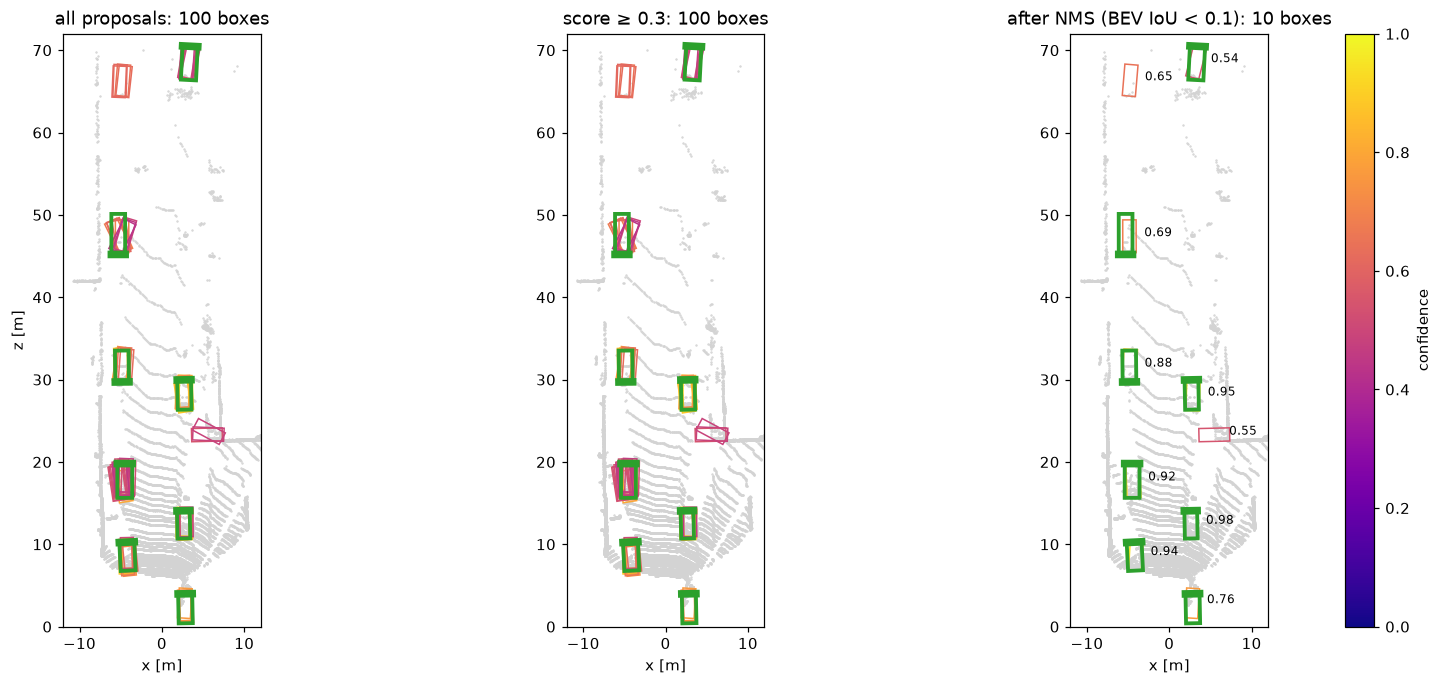

In [19]:
from utils.task5 import nms, bev_iou
import utils.eval as ev
import contextlib, io

ecfg = config['eval']
keep_sc = F['score'] >= ecfg['t_score']
before, before_sc = F['det'][keep_sc], F['score'][keep_sc]
after, after_sc = nms(before, before_sc, ecfg['t_nms'])
print(f'frame {F["frame"]}: {len(F["det"])} proposals -> {len(before)} with score ≥ {ecfg["t_score"]} -> {len(after)} after NMS '
      f'({len(F["tgt"])} ground-truth cars)')

fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, boxes, sc, title in [(axes[0], F['det'], F['score'], 'all proposals'),
                             (axes[1], before, before_sc, f'score ≥ {ecfg["t_score"]}'),
                             (axes[2], after, after_sc.ravel(), f'after NMS (BEV IoU < {ecfg["t_nms"]})')]:
    ax.scatter(F['xyz'][:, 0], F['xyz'][:, 2], c='lightgray', s=0.3)
    for b, s in zip(boxes, sc):
        draw_bev(ax, b[None], plt.get_cmap('plasma')(s), lw=1, front=False)
    draw_bev(ax, F['tgt'], 'tab:green', lw=2.5)
    ax.set_aspect('equal'); ax.set_xlim(-12, 12); ax.set_ylim(0, 72); ax.set_title(f'{title}: {len(boxes)} boxes')
    ax.set_xlabel('x [m]')
axes[0].set_ylabel('z [m]')
if len(after):
    for b, s in zip(after, after_sc.ravel()):
        axes[2].text(b[0] + 1.8, b[2], f'{s:.2f}', fontsize=8)
fig.colorbar(plt.cm.ScalarMappable(cmap='plasma', norm=plt.Normalize(0, 1)), ax=axes, label='confidence', fraction=0.02)
plt.show()

## 2.5.1 The algorithm step by step, on one car

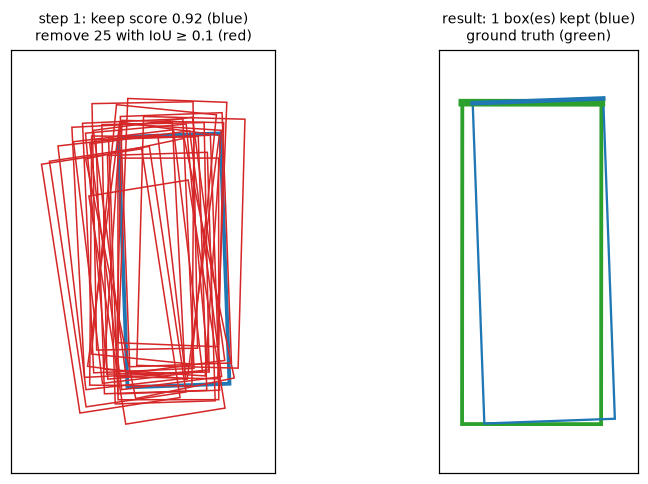

In [20]:
# Proposals around one ground-truth car
car = F['tgt'][int(np.argmax([np.sum(bev_iou(before, g[None])[:, 0] > 0.1) for g in F['tgt']]))]
cluster = bev_iou(before, car[None])[:, 0] > 0.05
Sp, Cp = before[cluster], before_sc[cluster]
steps = []
remaining = np.ones(len(Sp), bool)
while remaining.any():
    i = np.flatnonzero(remaining)[np.argmax(Cp[remaining])]
    overl = bev_iou(Sp[i:i + 1], Sp)[0]
    removed = remaining & (overl >= ecfg['t_nms']) & (np.arange(len(Sp)) != i)
    steps.append((i, removed.copy(), remaining.copy(), overl))
    remaining &= ~removed; remaining[i] = False

fig, axes = plt.subplots(1, len(steps) + 1, figsize=(4.2 * (len(steps) + 1), 4.5), squeeze=False)
axes = axes[0]
kept = []
for k, (i, removed, alive, overl) in enumerate(steps):
    ax = axes[k]
    for j in np.flatnonzero(alive):
        col = 'tab:red' if removed[j] else ('tab:blue' if j == i else 'lightgray')
        draw_bev(ax, Sp[j:j + 1], col, lw=2.5 if j == i else 1, front=False)
    for j in kept:
        draw_bev(ax, Sp[j:j + 1], 'tab:blue', lw=1.5, front=False, alpha=.5)
    ax.set_aspect('equal'); ax.autoscale_view(); ax.margins(.15); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f'step {k + 1}: keep score {Cp[i]:.2f} (blue)\nremove {removed.sum()} with IoU ≥ {ecfg["t_nms"]} (red)', fontsize=9)
    kept.append(i)
ax = axes[-1]
draw_bev(ax, car[None], 'tab:green', lw=2.5); draw_bev(ax, Sp[kept], 'tab:blue', lw=1.5)
ax.set_aspect('equal'); ax.autoscale_view(); ax.margins(.15); ax.set_xticks([]); ax.set_yticks([])
ax.set_title(f'result: {len(kept)} box(es) kept (blue)\nground truth (green)', fontsize=9)
plt.tight_layout(); plt.show()

## 2.5.2 Effect on the evaluation, and the choice of threshold

Running the stage-1 proposals (with their own scores) through the same path as `train.py` (score filter → NMS → `save_detections` → `compute_map`) gives the **baseline the trained second stage has to beat**.

The course's `utils/eval.py` measures car 3D AP at **IoU 0.5** (11 recall points). The official KITTI benchmark uses **IoU 0.7**, which is what really shows box precision, so both are reported here.

In [21]:
gt_annos = ev.get_gt_annos(ds.hf, ds.frames)
out_dir = os.path.join('output', 'nms_eval_tmp')

def evaluate(t_score, t_nms):
    '''Stage-1 proposals -> score filter -> NMS -> files -> KITTI 3D AP at IoU 0.5 and 0.7 (easy, moderate, hard).'''
    n_boxes = []
    for i, fr in enumerate(ds.frames):
        d = frame_data(i)
        if t_nms is None:
            p, s = d['det'][d['score'] >= t_score], d['score'][d['score'] >= t_score]
        else:
            p, s = ev.generate_final_predictions(d['det'], d['score'], {'t_score': t_score, 't_nms': t_nms})
        n_boxes.append(len(p))
        ev.save_detections(out_dir, fr, p, s)
    dt_annos = ev.get_pred_annos(out_dir, ds.frames)
    res = {'boxes/frame': np.mean(n_boxes)}
    for thr in [0.5, 0.7]:
        ov = np.zeros((1, 3, 1)); ov[0, :, 0] = [0.7 if thr == 0.7 else 0.5, thr, thr]
        with contextlib.redirect_stderr(io.StringIO()):
            _, _, ap, _ = ev.do_eval(gt_annos, dt_annos, [0], ov)
        res.update({f'AP@{thr} easy': ap[0, 0, 0], f'AP@{thr} moderate': ap[0, 1, 0], f'AP@{thr} hard': ap[0, 2, 0]})
    return res

baseline = pd.DataFrame({'no score filter, no NMS': evaluate(0.0, None),
                         f'score ≥ {ecfg["t_score"]}, NMS {ecfg["t_nms"]} (config)': evaluate(ecfg['t_score'], ecfg['t_nms'])}).T
baseline.round(2)

,boxes/frame,AP@0.5 easy,AP@0.5 moderate,AP@0.5 hard,AP@0.7 easy,AP@0.7 moderate,AP@0.7 hard
"no score filter, no NMS",100.00,30.83,29.27,28.91,28.54,25.94,25.91
"score ≥ 0.3, NMS 0.1 (config)",8.56,93.87,86.78,86.05,63.33,52.73,51.41


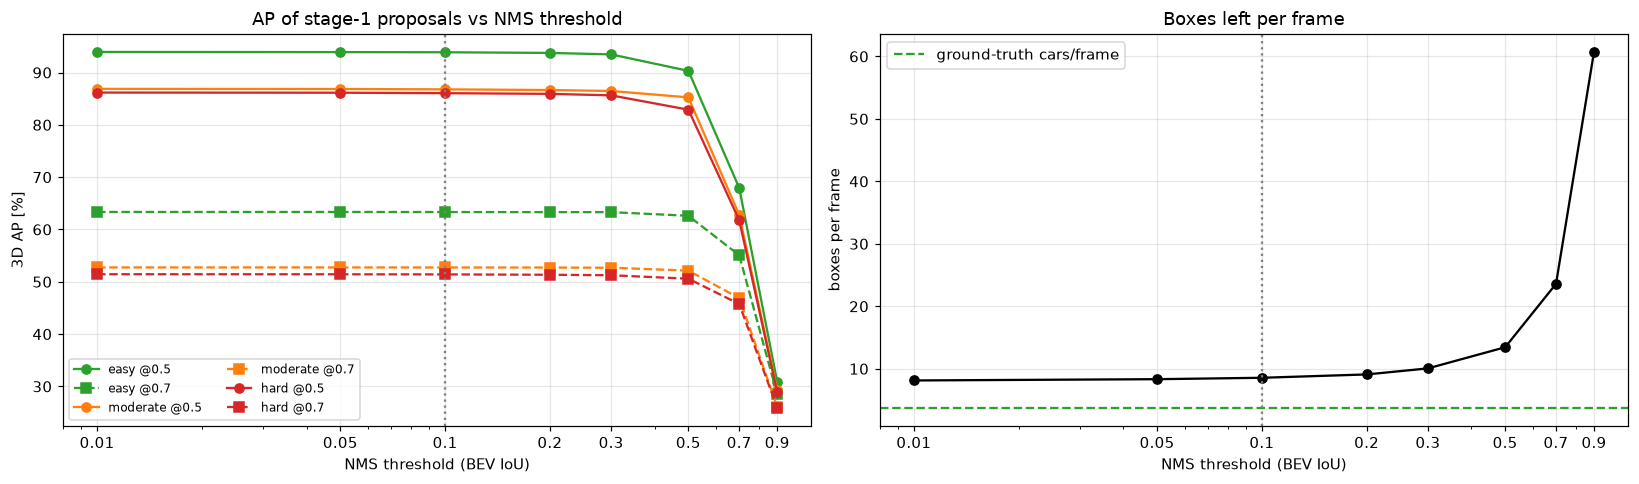

,boxes/frame,AP@0.5 easy,AP@0.5 moderate,AP@0.5 hard,AP@0.7 easy,AP@0.7 moderate,AP@0.7 hard
t_nms,,,,,,,
0.01,8.13,93.93,86.87,86.17,63.35,52.74,51.45
0.05,8.33,93.90,86.84,86.14,63.35,52.74,51.44
0.10,8.56,93.87,86.78,86.05,63.33,52.73,51.41
0.20,9.09,93.74,86.65,85.92,63.31,52.72,51.34
0.30,10.06,93.46,86.47,85.63,63.31,52.69,51.25
0.50,13.44,90.31,85.25,82.90,62.62,52.13,50.59
0.70,23.59,67.92,62.77,61.76,55.06,46.88,45.75
0.90,60.72,30.83,29.27,28.91,28.46,26.06,25.91


In [22]:
sweep = pd.DataFrame({t: evaluate(ecfg['t_score'], t) for t in [0.01, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9]}).T
sweep.index.name = 't_nms'

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for lvl, col in zip(['easy', 'moderate', 'hard'], ['tab:green', 'tab:orange', 'tab:red']):
    axes[0].plot(sweep.index, sweep[f'AP@0.5 {lvl}'], 'o-', color=col, label=f'{lvl} @0.5')
    axes[0].plot(sweep.index, sweep[f'AP@0.7 {lvl}'], 's--', color=col, label=f'{lvl} @0.7')
axes[0].axvline(ecfg['t_nms'], color='gray', ls=':'); axes[0].set_xscale('log'); axes[0].set_xticks(sweep.index, sweep.index)
axes[0].set_xlabel('NMS threshold (BEV IoU)'); axes[0].set_ylabel('3D AP [%]'); axes[0].legend(fontsize=8, ncol=2); axes[0].grid(alpha=.3)
axes[0].set_title('AP of stage-1 proposals vs NMS threshold')
axes[1].plot(sweep.index, sweep['boxes/frame'], 'o-k'); axes[1].axhline(np.mean([len(frame_data(i)['tgt']) for i in range(len(ds))]),
                                                                          color='tab:green', ls='--', label='ground-truth cars/frame')
axes[1].axvline(ecfg['t_nms'], color='gray', ls=':'); axes[1].set_xscale('log'); axes[1].set_xticks(sweep.index, sweep.index)
axes[1].set_xlabel('NMS threshold (BEV IoU)'); axes[1].set_ylabel('boxes per frame'); axes[1].legend(); axes[1].grid(alpha=.3)
axes[1].set_title('Boxes left per frame')
plt.tight_layout(); plt.show()
import shutil; shutil.rmtree(out_dir, ignore_errors=True)
sweep.round(2)

How to read this:
* **NMS matters enormously**: without it, every car has several detections and all but one count as false positives (AP about 30). With it, AP@0.5 jumps to about 94 / 87 / 86.
* **Low thresholds are right for cars**: real cars never overlap from above, so any overlap > 0.1 is almost certainly a duplicate. Higher thresholds keep duplicates and AP drops.
* **The bar for the second stage**: on minival, the stage-1 proposals alone reach about **94 / 87 / 86 at IoU 0.5** but only **63 / 53 / 51 at IoU 0.7**. This first stage is much stronger than the course's (recall 0.93 vs 0.80 on the course's recorded val frames), so the course's expected 63 / 63 / 59 isn't a meaningful target here. Refinement shows its value at IoU 0.7: logging AP@0.7 during training as well would make that visible (the 0.7 setting is commented out in `utils/eval.py → get_official_eval_result`).

## 2.5.3 Report questions

**1. Must the IoU be computed in BEV, or could it be 3D?** Either works. On this data the result is practically identical (AP@0.5 moderate 86.78 with both), because all cars stand on the ground and have similar heights, so their vertical ranges almost always overlap fully.

**2. Advantages of BEV over 3D (and vice versa) for NMS?**
* *BEV:* two cars can't occupy the same ground area, so overlap from above is exactly the notion of "same object". It's robust to errors in the predicted height and vertical position (two duplicates with different heights could have a low 3D IoU and survive 3D NMS), and it's cheaper.
* *3D:* it would keep objects that are stacked vertically (not a concern for cars on a road, but relevant e.g. for objects under bridges or on multi-level structures), and it matches the 3D evaluation metric.